CNNs no **Beans Dataset**

**Generalização, transfer learning e investigação de previsões**

**Problema:** classificar uma fotografia de folha de feijão em **mancha-angular**, **ferrugem** ou **saudável**.

Este material é um **estudo guiado**. A sequência é: observar dados → formular uma hipótese → executar um experimento → interpretar resultados → identificar limitações. As explicações foram escritas para quem já viu `Conv2D`, `Dense`, `compile()` e `fit()`, mas está começando a trabalhar com CNNs.

> **Importante:** as curvas, matrizes, pontuações e mapas deste notebook serão produzidos **pelos modelos treinados ao executar as células**. Não há resultados numéricos experimentais inventados.

**Fonte dos dados:** [Beans — Makerere AI Lab no Hugging Face](https://huggingface.co/datasets/AI-Lab-Makerere/beans), com as divisões oficiais documentadas pelo [TensorFlow Datasets](https://www.tensorflow.org/datasets/catalog/beans). **Grad-CAM:** [exemplo oficial do Keras](https://keras.io/examples/vision/grad_cam/). **Fine-tuning:** [guia oficial do Keras](https://keras.io/guides/transfer_learning/).

## Como usar este notebook

- Execute as células **de cima para baixo** em um Colab com **GPU** (`Ambiente de execução > Alterar tipo de ambiente de execução`). Uma GPU ajuda, mas a base é pequena e o material também pode ser explorado em CPU, mais lentamente.
- **Fonte de dados:** usaremos a cópia pública do Beans mantida no [Hugging Face por AI-Lab-Makerere](https://huggingface.co/datasets/AI-Lab-Makerere/beans). O endereço antigo de download do TensorFlow Datasets (`storage.googleapis.com/ibeans/train.zip`) retorna HTTP 403. A origem alternativa preserva os splits oficiais: 1.034/133/128. A biblioteca `datasets` lê as imagens e as convertemos para `tf.data.Dataset`, mantendo o restante dos exemplos em Keras.
- A primeira execução baixa os dados e, mais adiante, os pesos da MobileNetV2. É necessário acesso à internet.
- Cada experimento contém uma pergunta, uma hipótese e perguntas de interpretação. **Tente prever o resultado antes do treino.**
- O teste oficial permanece reservado: só será avaliado ao final, depois de decidirmos o modelo usando validação. A leitura de assinaturas das imagens de teste para *auditoria de duplicatas* não envolve escolher hiperparâmetros.
- O estudo principal treina várias redes; se estiver apresentando em aula, execute os treinamentos antes e utilize suas saídas reais salvas. Uma execução completa pode levar tempo, mesmo no Colab com GPU.

## 0. Ambiente, configurações e reprodutibilidade

Instalaremos `datasets` para carregar a cópia pública do Beans no Hugging Face. Também utilizaremos `tensorflow_datasets` para converter iteradores `tf.data` em arrays durante o EDA, mas **não** para baixar o Beans, pois seu endereço original está indisponível (HTTP 403).

O TensorFlow costuma vir pré-instalado no Colab. Registraremos as versões e fixaremos uma semente. Sementes ajudam na comparação, mas não garantem resultados bit a bit idênticos entre dispositivos.

In [1]:
%pip -q install tensorflow-datasets datasets importlib_resources

In [2]:
import hashlib
import random
import time
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy.fft import dctn
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             confusion_matrix, f1_score, recall_score)
import tensorflow as tf
import tensorflow_datasets as tfds
from datasets import load_dataset
from tensorflow import keras
from tensorflow.keras import layers, regularizers

SEMENTE_ALEATORIA = 42
ALTURA_IMAGEM = 160
LARGURA_IMAGEM = 160
TAMANHO_LOTE = 32
EPOCAS_CNN_INICIAL = 25
EPOCAS_MODELOS_REGULARIZADOS = 25
EPOCAS_TRANSFERENCIA = 20
EPOCAS_AJUSTE_FINO = 12
EPOCAS_ATALHO = 16

random.seed(SEMENTE_ALEATORIA)
np.random.seed(SEMENTE_ALEATORIA)
tf.keras.utils.set_random_seed(SEMENTE_ALEATORIA)

print('TensorFlow:', tf.__version__)
print('TFDS:', tfds.__version__)
print('Hugging Face Datasets: instalado')
print('Dispositivos GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
TFDS: 4.9.10
Hugging Face Datasets: instalado
Dispositivos GPU: []


## 1. EDA

**Pergunta:** o que entra na CNN, quantas classes existem e o que muda visualmente de uma fotografia para outra?

O Beans possui divisões oficiais `train`, `validation` e `test`. Mantemos essas divisões ao carregar a cópia publicada no Hugging Face. A biblioteca `datasets` fornece cada imagem como objeto PIL e o rótulo `labels`; convertemos cada exemplo para o par `(imagem, rotulo)` em `tf.data.Dataset`, que é o formato esperado pelas próximas células.

**Não normalizamos ainda:** queremos inspecionar os pixels originais antes do pré-processamento.

In [3]:
# Fonte alternativa para o Beans: os ZIPs originais do TFDS retornam HTTP 403.
# O repositório no Hugging Face fornece os mesmos splits em Parquet.
colecao_beans_huggingface = load_dataset('AI-Lab-Makerere/beans')
nomes_classes = list(colecao_beans_huggingface['train'].features['labels'].names)
numero_classes = len(nomes_classes)

quantidades_oficiais = {
    nome_split: len(colecao_beans_huggingface[nome_split])
    for nome_split in ('train', 'validation', 'test')
}


def converter_split_para_tfdata(nome_split):
    """Converte o split HF em pares (imagem RGB uint8, rótulo int64).

    A ordem original de cada split é preservada; o shuffle fica apenas
    para o pipeline de treinamento, preparado mais adiante no notebook.
    """
    registros_split = colecao_beans_huggingface[nome_split]

    def gerar_imagens_e_rotulos():
        for registro in registros_split:
            imagem_rgb = np.asarray(registro['image'].convert('RGB'), dtype=np.uint8)
            rotulo_inteiro = np.int64(registro['labels'])
            yield imagem_rgb, rotulo_inteiro

    return tf.data.Dataset.from_generator(
        gerar_imagens_e_rotulos,
        output_signature=(
            tf.TensorSpec(shape=(None, None, 3), dtype=tf.uint8),
            tf.TensorSpec(shape=(), dtype=tf.int64),
        ),
    )


dados_treinamento_brutos = converter_split_para_tfdata('train')
dados_validacao_brutos = converter_split_para_tfdata('validation')
dados_teste_brutos = converter_split_para_tfdata('test')

print('Classes, na ordem dos rótulos:', nomes_classes)
print('Exemplos por divisão:', quantidades_oficiais)
print('Especificação de uma imagem:', dados_treinamento_brutos.element_spec[0])

assert nomes_classes == ['angular_leaf_spot', 'bean_rust', 'healthy']
assert quantidades_oficiais == {'train': 1034, 'validation': 133, 'test': 128}

README.md:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  144MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.5MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1034 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/133 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/128 [00:00<?, ? examples/s]

Classes, na ordem dos rótulos: ['angular_leaf_spot', 'bean_rust', 'healthy']
Exemplos por divisão: {'train': 1034, 'validation': 133, 'test': 128}
Especificação de uma imagem: TensorSpec(shape=(None, None, 3), dtype=tf.uint8, name=None)


Shape da imagem: (500, 500, 3)
Tipo numérico: <dtype: 'uint8'>
Menor pixel: 0
Maior pixel: 255
Rótulo inteiro: 0
Classe: angular_leaf_spot


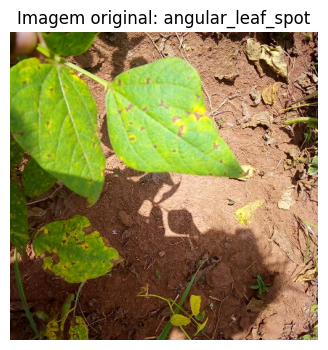

In [4]:
imagem_exemplo_bruta, rotulo_exemplo_bruto = next(iter(dados_treinamento_brutos))

print('Shape da imagem:', imagem_exemplo_bruta.shape)
print('Tipo numérico:', imagem_exemplo_bruta.dtype)
print('Menor pixel:', int(tf.reduce_min(imagem_exemplo_bruta)))
print('Maior pixel:', int(tf.reduce_max(imagem_exemplo_bruta)))
print('Rótulo inteiro:', int(rotulo_exemplo_bruto))
print('Classe:', nomes_classes[int(rotulo_exemplo_bruto)])

plt.figure(figsize=(5, 4))
plt.imshow(imagem_exemplo_bruta.numpy())
plt.title(f'Imagem original: {nomes_classes[int(rotulo_exemplo_bruto)]}')
plt.axis('off')
plt.show()

### 1.1 Ver várias imagens por classe

Uma fotografia por classe seria insuficiente para entender o problema. Observe **variação de cor, intensidade das lesões, posição da folha, fundo e luz**. A amostragem abaixo usa imagens do **treinamento**, não do teste.

**Antes de executar:** quais características você acha que a CNN poderá aprender? E quais características poderiam virar atalhos, por exemplo, uma diferença sistemática de fundo?

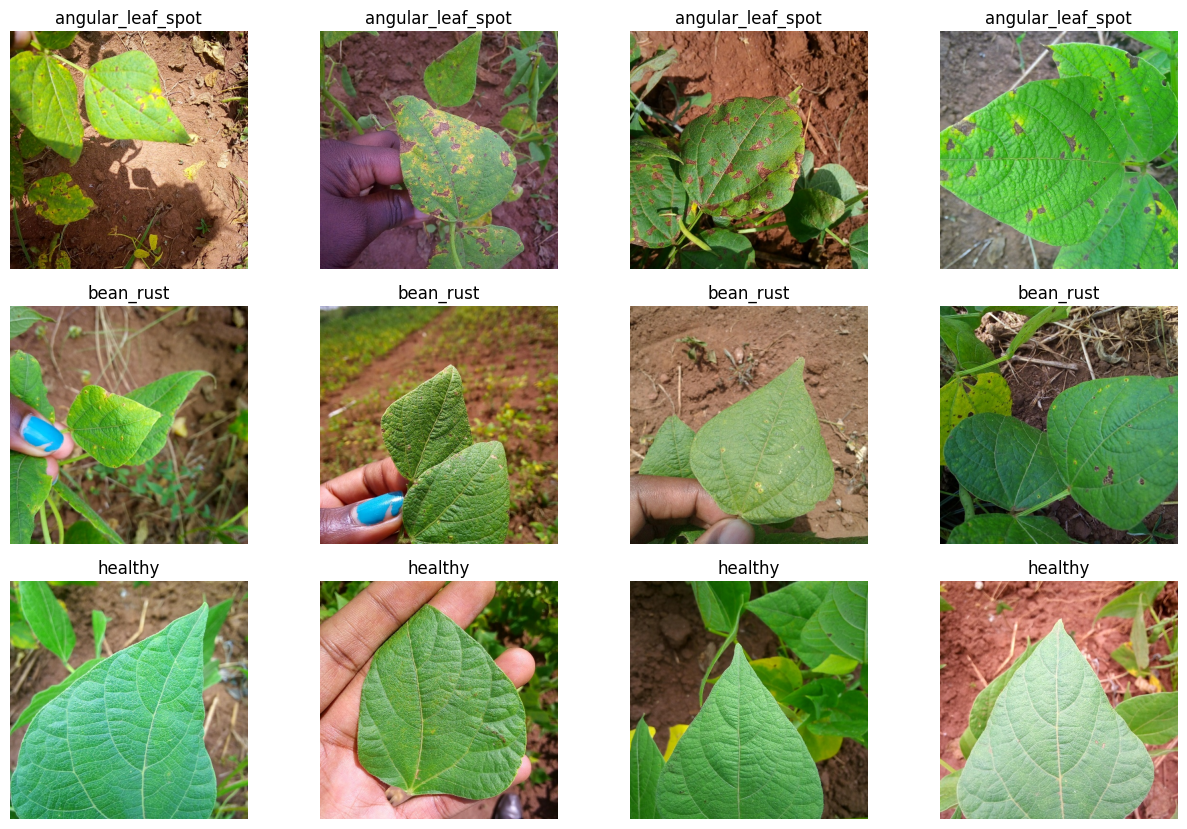

In [5]:
def visualizar_exemplos_por_classe(dataset_bruto, nomes_classes, exemplos_por_classe=4):
    imagens_por_classe = defaultdict(list)
    for imagem, rotulo in tfds.as_numpy(dataset_bruto):
        indice_classe = int(rotulo)
        if len(imagens_por_classe[indice_classe]) < exemplos_por_classe:
            imagens_por_classe[indice_classe].append(imagem)
        if all(len(imagens_por_classe[indice]) == exemplos_por_classe
               for indice in range(len(nomes_classes))):
            break

    figura, eixos = plt.subplots(len(nomes_classes), exemplos_por_classe,
                                figsize=(3.2 * exemplos_por_classe,
                                         2.8 * len(nomes_classes)), squeeze=False)
    for indice_classe, nome_classe in enumerate(nomes_classes):
        for coluna, imagem in enumerate(imagens_por_classe[indice_classe]):
            eixos[indice_classe, coluna].imshow(imagem)
            eixos[indice_classe, coluna].set_title(nome_classe)
            eixos[indice_classe, coluna].axis('off')
    plt.tight_layout()
    plt.show()

visualizar_exemplos_por_classe(dados_treinamento_brutos, nomes_classes)

### 1.2 Contagem por classe e baseline ingênua

Se quase todas as fotografias fossem de folhas saudáveis, acertar sempre "saudável" poderia gerar uma acurácia aparentemente elevada. Vamos contar as classes **no conjunto de treinamento** e calcular o desempenho de um classificador que sempre escolhe a classe majoritária.

,classe,imagens_treinamento
0,angular_leaf_spot,345
1,bean_rust,348
2,healthy,341


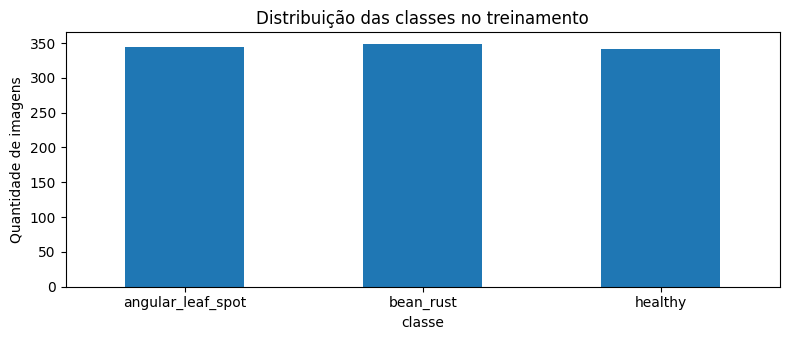

Acurácia da estratégia majoritária NO TREINO: 33.7%
Isto é uma referência ingênua, não uma métrica de generalização.


In [6]:
contagens_classes_treinamento = Counter(
    int(rotulo) for _, rotulo in tfds.as_numpy(dados_treinamento_brutos)
)
contagem_por_classe = pd.DataFrame({
    'classe': nomes_classes,
    'imagens_treinamento': [contagens_classes_treinamento[indice]
                            for indice in range(numero_classes)],
})
display(contagem_por_classe)

contagem_por_classe.plot.bar(x='classe', y='imagens_treinamento',
                            legend=False, figsize=(8, 3.5), rot=0)
plt.ylabel('Quantidade de imagens')
plt.title('Distribuição das classes no treinamento')
plt.tight_layout()
plt.show()

acuracia_classe_majoritaria_treino = max(contagens_classes_treinamento.values()) / sum(contagens_classes_treinamento.values())
print(f'Acurácia da estratégia majoritária NO TREINO: {acuracia_classe_majoritaria_treino:.1%}')
print('Isto é uma referência ingênua, não uma métrica de generalização.')

### 1.3 Qualidade das fotografias e luminosidade

Um EDA útil não precisa de dezenas de histogramas. Vamos visualizar **extremos de luminosidade** (estimativa da média dos canais RGB) e discutir se isso pode dificultar o reconhecimento. Essa média **não detecta automaticamente** uma imagem de baixa qualidade; é apenas um indicador exploratório.

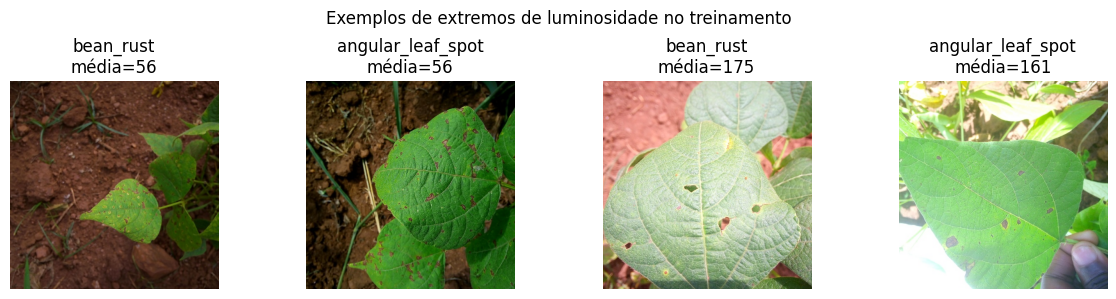

In [7]:
resumos_luminosidade = []
for indice_imagem, (imagem, rotulo) in enumerate(tfds.as_numpy(dados_treinamento_brutos)):
    # Reduzir espacialmente antes de computar uma estatística aproximada.
    imagem_amostrada = imagem[::10, ::10, :]
    resumos_luminosidade.append({
        'indice': indice_imagem,
        'rotulo': int(rotulo),
        'luminosidade_media': float(np.mean(imagem_amostrada)),
    })

tabela_luminosidade = pd.DataFrame(resumos_luminosidade)
indices_extremos = pd.concat([
    tabela_luminosidade.nsmallest(2, 'luminosidade_media'),
    tabela_luminosidade.nlargest(2, 'luminosidade_media'),
])
indices_para_mostrar = set(indices_extremos['indice'].tolist())
imagens_extremas = {}
for indice_imagem, (imagem, _) in enumerate(tfds.as_numpy(dados_treinamento_brutos)):
    if indice_imagem in indices_para_mostrar:
        imagens_extremas[indice_imagem] = imagem
    if len(imagens_extremas) == len(indices_para_mostrar):
        break

figura, eixos = plt.subplots(1, len(indices_extremos), figsize=(12, 3))
for eixo, (_, linha) in zip(eixos, indices_extremos.iterrows()):
    eixo.imshow(imagens_extremas[int(linha['indice'])])
    eixo.set_title(f"{nomes_classes[int(linha['rotulo'])]}\nmédia={linha['luminosidade_media']:.0f}")
    eixo.axis('off')
plt.suptitle('Exemplos de extremos de luminosidade no treinamento')
plt.tight_layout()
plt.show()

**Perguntas para responder antes de avançar**

1. As classes parecem próximas do equilíbrio? O classificador ingênuo seria uma boa solução?
2. Quais diferenças dentro da mesma classe podem prejudicar a CNN?
3. O fundo das fotos pode fornecer pistas que não representam a doença?
4. A cor, sozinha, seria suficiente para diferenciar as três classes? Justifique usando exemplos observados.

## 2. Auditoria de vazamento

**Problema:** se imagens idênticas (ou quase idênticas) estiverem em treino e validação/teste, a avaliação pode ser excessivamente otimista.

Vamos realizar duas verificações:

- **SHA-256 dos pixels decodificados:** detecta imagens exatamente iguais, mesmo se tiverem nomes diferentes.
- **Hash perceptual (pHash):** sinaliza possíveis quase duplicatas entre os splits. É um *filtro de candidatos*, não uma decisão automática.

A auditoria de teste examina somente a integridade das imagens — **não** suas previsões ou desempenho. Ela não será utilizada para escolher parâmetros. O dataset público não fornece um identificador confiável de planta/fazenda/sessão de captura; por isso **não podemos garantir independência por planta**.

> A auditoria pode levar algum tempo na primeira execução. Não carregaremos todas as imagens 500×500 em memória simultaneamente.

In [8]:
def assinatura_perceptual(imagem_numpy):
    """pHash 64 bits com DCT: mede semelhança aproximada, NÃO equivalência."""
    imagem_cinza = Image.fromarray(imagem_numpy).convert('L').resize((32, 32))
    coeficientes = dctn(np.asarray(imagem_cinza, dtype=np.float32), norm='ortho')
    frequencias_baixas = coeficientes[:8, :8].reshape(-1)
    mediana_frequencias = np.median(frequencias_baixas[1:])  # ignora DC na mediana
    bits = frequencias_baixas > mediana_frequencias
    assinatura = 0
    for bit in bits:
        assinatura = (assinatura << 1) | int(bit)
    return assinatura


def auditar_assinaturas_split(dataset_bruto, nome_split):
    registros = []
    for indice, (imagem, _) in enumerate(tfds.as_numpy(dataset_bruto)):
        # A dimensão entra no digest para distinguir formatos de bytes coincidentes.
        bytes_dimensoes = np.asarray(imagem.shape, dtype=np.int32).tobytes()
        assinatura_exata = hashlib.sha256(bytes_dimensoes + imagem.tobytes()).hexdigest()
        registros.append({
            'split': nome_split,
            'indice': indice,
            'sha256': assinatura_exata,
            'phash': assinatura_perceptual(imagem),
        })
    return registros

registros_assinaturas = (
    auditar_assinaturas_split(dados_treinamento_brutos, 'train')
    + auditar_assinaturas_split(dados_validacao_brutos, 'validation')
    + auditar_assinaturas_split(dados_teste_brutos, 'test')
)
tabela_assinaturas = pd.DataFrame(registros_assinaturas)
assert len(tabela_assinaturas) == sum(quantidades_oficiais.values())

sha_para_registros = defaultdict(list)
for registro in registros_assinaturas:
    sha_para_registros[registro['sha256']].append(registro)

duplicatas_exatas = [grupo for grupo in sha_para_registros.values()
                    if len({item['split'] for item in grupo}) > 1]
print('Grupos de imagens com pixels IDÊNTICOS entre splits:', len(duplicatas_exatas))
for grupo in duplicatas_exatas[:6]:
    print([(item['split'], item['indice']) for item in grupo])

Grupos de imagens com pixels IDÊNTICOS entre splits: 0


In [9]:
# Compare somente pares entre splits distintos. Distância de Hamming baixa
# sugere semelhança, mas não prova que duas fotos sejam duplicadas.
LIMIAR_PHASH = 8  # valor heurístico para gerar candidatos, NÃO critério definitivo
LIMITE_PARES_SUSPEITOS = 15

registros_por_split = {
    nome_split: [registro for registro in registros_assinaturas if registro['split'] == nome_split]
    for nome_split in ('train', 'validation', 'test')
}
pares_suspeitos = []
for nome_primeiro, nome_segundo in [('train', 'validation'), ('train', 'test'),
                                   ('validation', 'test')]:
    for primeiro in registros_por_split[nome_primeiro]:
        for segundo in registros_por_split[nome_segundo]:
            distancia = (primeiro['phash'] ^ segundo['phash']).bit_count()
            if distancia <= LIMIAR_PHASH:
                pares_suspeitos.append({
                    'split_a': nome_primeiro, 'indice_a': primeiro['indice'],
                    'split_b': nome_segundo, 'indice_b': segundo['indice'],
                    'distancia_phash': distancia,
                })

pares_suspeitos.sort(key=lambda registro: registro['distancia_phash'])
print(f'Pares candidatos com pHash <= {LIMIAR_PHASH}:', len(pares_suspeitos))
display(pd.DataFrame(pares_suspeitos[:LIMITE_PARES_SUSPEITOS]))

Pares candidatos com pHash <= 8: 0


""


### Revisar visualmente os candidatos

O código seguinte só exibe pares encontrados. **Não exclui nem mistura os conjuntos automaticamente.** Se houver sobreposição, registre-a no relatório e discuta que a avaliação oficial pode ficar comprometida. Remover exemplos ou refazer splits depois de ver o teste precisaria de um protocolo novo, claramente identificado.

In [10]:
def obter_imagem_por_indice(dataset_bruto, indice_desejado):
    for indice, (imagem, _) in enumerate(tfds.as_numpy(dataset_bruto)):
        if indice == indice_desejado:
            return imagem
    raise IndexError('Índice não encontrado no dataset.')

splits_brutos = {
    'train': dados_treinamento_brutos,
    'validation': dados_validacao_brutos,
    'test': dados_teste_brutos,
}

if not pares_suspeitos:
    print('Nenhum candidato foi sinalizado pelo limiar definido. Isso NÃO prova ausência de duplicatas.')
else:
    for candidato in pares_suspeitos[:3]:
        imagem_a = obter_imagem_por_indice(splits_brutos[candidato['split_a']], candidato['indice_a'])
        imagem_b = obter_imagem_por_indice(splits_brutos[candidato['split_b']], candidato['indice_b'])
        figura, eixos = plt.subplots(1, 2, figsize=(8, 3))
        eixos[0].imshow(imagem_a)
        eixos[1].imshow(imagem_b)
        eixos[0].set_title(f"{candidato['split_a']} · {candidato['indice_a']}")
        eixos[1].set_title(f"{candidato['split_b']} · {candidato['indice_b']}")
        for eixo in eixos:
            eixo.axis('off')
        plt.suptitle(f"Distância pHash = {candidato['distancia_phash']}; revisão humana necessária")
        plt.tight_layout()
        plt.show()

Nenhum candidato foi sinalizado pelo limiar definido. Isso NÃO prova ausência de duplicatas.


### Checklist contra vazamento

- [x] Splits oficiais carregados separadamente.
- [x] Auditoria de duplicatas exatas e candidatos perceptuais (resultados dependem da execução).
- [ ] Nenhum resultado do **teste** será usado para ajustar os modelos.
- [ ] Qualquer transformação que aprenda estatísticas será ajustada apenas no treino.
- [ ] Aumentação ocorrerá apenas no treino; validação e teste não terão transformações aleatórias.
- [ ] Nenhuma versão aumentada de uma imagem será colocada em outro split.

**Questão para discussão:** se duas fotos forem da mesma folha, tiradas de ângulos diferentes, uma auditoria com hashes é suficiente para provar independência? Não. Seriam necessários metadados de origem para separação agrupada.

## 3. Preparação

**Pergunta:** qual é o formato exato entregue para `model.fit()`?

Todas as imagens passam por **redimensionamento para 160×160** e conversão para `float32`, mantendo a escala 0–255. A normalização será feita **dentro de cada arquitetura**: CNN do zero (`Rescaling(1/255)`) e MobileNetV2 (`valor/127.5 - 1`). Isso evita normalizar duas vezes.

`shuffle()` será utilizado somente no treinamento. Os conjuntos de validação e teste permanecerão determinísticos. Reservaremos a criação do pipeline de **teste** para a última seção.

In [11]:
def preparar_imagem(imagem, rotulo):
    imagem_redimensionada = tf.image.resize(
        imagem, [ALTURA_IMAGEM, LARGURA_IMAGEM], antialias=True
    )
    imagem_redimensionada = tf.ensure_shape(imagem_redimensionada, [ALTURA_IMAGEM, LARGURA_IMAGEM, 3])
    rotulo_inteiro = tf.cast(rotulo, tf.int32)
    return tf.cast(imagem_redimensionada, tf.float32), rotulo_inteiro


def preparar_dataset(dataset_bruto, treinamento=False):
    dataset = dataset_bruto.map(preparar_imagem, num_parallel_calls=tf.data.AUTOTUNE)
    # Cache APÓS o resize para não reler e decodificar JPEG em toda época.
    # Aumentação aleatória acontece DENTRO do modelo, após este cache.
    dataset = dataset.cache()
    if treinamento:
        dataset = dataset.shuffle(
            buffer_size=quantidades_oficiais['train'],
            seed=SEMENTE_ALEATORIA,
            reshuffle_each_iteration=True,
        )
    return dataset.batch(TAMANHO_LOTE).prefetch(tf.data.AUTOTUNE)


dados_treinamento = preparar_dataset(dados_treinamento_brutos, treinamento=True)
dados_validacao = preparar_dataset(dados_validacao_brutos)

lote_imagens, lote_rotulos = next(iter(dados_treinamento))
assert lote_imagens.shape[1:] == (ALTURA_IMAGEM, LARGURA_IMAGEM, 3)
assert lote_imagens.dtype == tf.float32
assert bool(tf.reduce_all(lote_rotulos >= 0)) and bool(tf.reduce_all(lote_rotulos < numero_classes))
assert 0 <= float(tf.reduce_min(lote_imagens)) <= 255
assert 0 <= float(tf.reduce_max(lote_imagens)) <= 255
print('Shape de um LOTE:', lote_imagens.shape)
print('Shape dos RÓTULOS:', lote_rotulos.shape)
print('Faixa dos pixels após resize:', float(tf.reduce_min(lote_imagens)),
      'a', float(tf.reduce_max(lote_imagens)))

Shape de um LOTE: (32, 160, 160, 3)
Shape dos RÓTULOS: (32,)
Faixa dos pixels após resize: 0.0 a 255.0


## 4. Experimento 1: CNN treinada do zero

**Pergunta:** uma CNN pequena consegue reconhecer as doenças usando somente as nossas imagens?

**Hipótese para registrar antes de executar:** com pouco mais de mil imagens, o modelo pode aprender, mas também pode ficar muito melhor no treino do que na validação.

Arquitetura inicial: `Conv2D(32) → MaxPool → Conv2D(64) → MaxPool → Conv2D(128) → MaxPool → GlobalAveragePooling2D → Dense(3)`.

A última `Dense` produz **três logits** (pontuações não normalizadas). Usaremos `SparseCategoricalCrossentropy(from_logits=True)` porque os rótulos são inteiros e cada folha pertence a exatamente uma classe. Na hora de exibir probabilidades, aplicaremos `softmax`.

In [12]:
def construir_cnn(usar_dropout=False, usar_regularizacao_l2=False,
                  taxa_dropout=0.3, intensidade_l2=1e-4,
                  camada_aumentacao=None):
    entrada_imagem = keras.Input(shape=(ALTURA_IMAGEM, LARGURA_IMAGEM, 3),
                                 name='imagem_rgb')
    caracteristicas = entrada_imagem
    if camada_aumentacao is not None:
        # Camadas Keras de aumentação agem durante fit(), não em predict().
        caracteristicas = camada_aumentacao(caracteristicas)
    caracteristicas = layers.Rescaling(1.0 / 255.0, name='normalizar_0_1')(caracteristicas)

    for numero_filtros in (32, 64, 128):
        caracteristicas = layers.Conv2D(
            numero_filtros, kernel_size=3, padding='same', activation='relu'
        )(caracteristicas)
        caracteristicas = layers.MaxPooling2D(pool_size=2)(caracteristicas)

    caracteristicas = layers.GlobalAveragePooling2D()(caracteristicas)
    if usar_dropout:
        caracteristicas = layers.Dropout(taxa_dropout)(caracteristicas)
    penalizacao = regularizers.l2(intensidade_l2) if usar_regularizacao_l2 else None
    pontuacoes_classes = layers.Dense(
        numero_classes, kernel_regularizer=penalizacao,
        name='logits_classes'
    )(caracteristicas)
    return keras.Model(entrada_imagem, pontuacoes_classes, name='cnn_folhas')


def compilar_modelo(modelo, taxa_aprendizado):
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=taxa_aprendizado),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name='acuracia')],
    )


def criar_callbacks(paciencia=4):
    return [
        keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=paciencia,
            min_delta=0.001, restore_best_weights=True,
        ),
        keras.callbacks.TerminateOnNaN(),
    ]


def plotar_curvas_treinamento(historico, titulo):
    epocas = np.arange(1, len(historico.history['loss']) + 1)
    figura, eixos = plt.subplots(1, 2, figsize=(12, 4))
    eixos[0].plot(epocas, historico.history['loss'], label='Treinamento')
    eixos[0].plot(epocas, historico.history['val_loss'], label='Validação')
    eixos[0].set_title('Perda (loss)')
    eixos[1].plot(epocas, historico.history['acuracia'], label='Treinamento')
    eixos[1].plot(epocas, historico.history['val_acuracia'], label='Validação')
    eixos[1].set_title('Acurácia')
    for eixo in eixos:
        eixo.set_xlabel('Época')
        eixo.legend()
        eixo.grid(alpha=0.25)
    figura.suptitle(titulo)
    plt.tight_layout()
    plt.show()

Model: "cnn_folhas"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagem_rgb (InputLayer)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalizar_0_1 (Rescaling)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits_classes (Dense)          │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,635 (365.76 KB)

 Trainable params: 93,635 (365.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


33/33 - 83s - 3s/step - acuracia: 0.4323 - loss: 1.0616 - val_acuracia: 0.5639 - val_loss: 0.9525
Epoch 2/25
33/33 - 68s - 2s/step - acuracia: 0.5803 - loss: 0.9336 - val_acuracia: 0.5789 - val_loss: 0.9548
Epoch 3/25
33/33 - 80s - 2s/step - acuracia: 0.5503 - loss: 0.9431 - val_acuracia: 0.5865 - val_loss: 0.8821
Epoch 4/25
33/33 - 65s - 2s/step - acuracia: 0.6335 - loss: 0.8605 - val_acuracia: 0.6842 - val_loss: 0.8157
Epoch 5/25
33/33 - 64s - 2s/step - acuracia: 0.6557 - loss: 0.8386 - val_acuracia: 0.7068 - val_loss: 0.7980
Epoch 6/25
33/33 - 82s - 2s/step - acuracia: 0.6441 - loss: 0.8097 - val_acuracia: 0.6165 - val_loss: 0.7495
Epoch 7/25
33/33 - 82s - 2s/step - acuracia: 0.6412 - loss: 0.8134 - val_acuracia: 0.7368 - val_loss: 0.7439
Epoch 8/25
33/33 - 64s - 2s/step - acuracia: 0.6692 - loss: 0.7483 - val_acuracia: 0.5564 - val_loss: 0.7742
Epoch 9/25
33/33 - 72s - 2s/step - acuracia: 0.6973 - loss: 0.7198 - val_acuracia: 0.7068 - val_loss: 0.7197
Epoch 10/25
33/33 - 82s - 2s/s

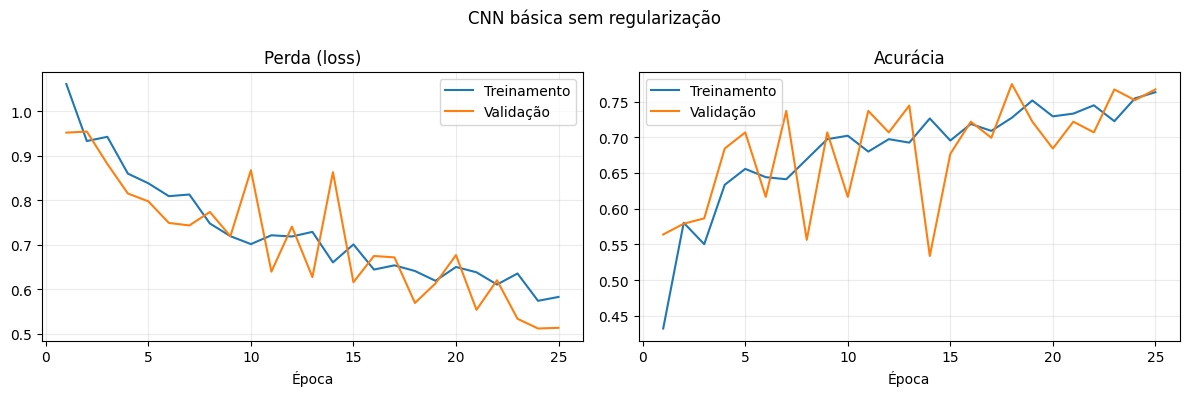

In [13]:
tf.keras.utils.set_random_seed(SEMENTE_ALEATORIA)
modelo_cnn_basico = construir_cnn()
compilar_modelo(modelo_cnn_basico, taxa_aprendizado=1e-3)
modelo_cnn_basico.summary()

inicio_treinamento = time.perf_counter()
historico_cnn_basico = modelo_cnn_basico.fit(
    dados_treinamento,
    validation_data=dados_validacao,
    epochs=EPOCAS_CNN_INICIAL,
    verbose=2,
)
tempo_cnn_basico = time.perf_counter() - inicio_treinamento
plotar_curvas_treinamento(historico_cnn_basico, 'CNN básica sem regularização')

### Interprete o primeiro resultado

1. A perda de validação diminui até o fim, ou começa a subir?
2. Se a acurácia de treino aumenta e a de validação estagna, isso é evidência de quê?
3. Por que a acurácia de treino sozinha não mede generalização?

**Não altere os hiperparâmetros ainda.** Primeiro vamos diagnosticar o comportamento que acabamos de observar.

## 5. Experimento 2: Diagnosticar erros e sobreajuste

**Pergunta:** *quais* classes o modelo confunde? Uma acurácia agregada não responde isso.

Usaremos somente a **validação**, e criaremos funções para reutilizar nos experimentos seguintes. As previsões retornadas pelo modelo são logits; `argmax` encontra a classe prevista e `softmax` produz probabilidades. O recall por classe responde: "de todas as imagens realmente dessa classe, quantas foram identificadas corretamente?".

CNN básica: acurácia de validação = 76.7%; F1 macro = 0.764
modelo                      CNN básica
acuracia                      0.766917
f1_macro                      0.764151
recall_angular_leaf_spot      0.590909
recall_bean_rust                   0.8
recall_healthy                0.909091
epocas                              25
tempo_segundos                  1873.8
parametros_treinaveis            93635


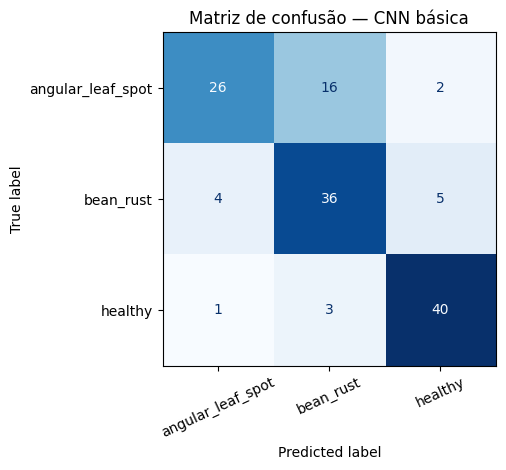

In [15]:
def coletar_previsoes(modelo, dataset):
    rotulos_verdadeiros = []
    pontuacoes_previstas = []
    for imagens_lote, rotulos_lote in dataset:
        logits_lote = modelo(imagens_lote, training=False)
        rotulos_verdadeiros.append(rotulos_lote.numpy())
        pontuacoes_previstas.append(logits_lote.numpy())
    rotulos_verdadeiros = np.concatenate(rotulos_verdadeiros)
    pontuacoes_previstas = np.concatenate(pontuacoes_previstas)
    probabilidades_previstas = tf.nn.softmax(pontuacoes_previstas, axis=-1).numpy()
    classes_previstas = np.argmax(pontuacoes_previstas, axis=1)
    return rotulos_verdadeiros, classes_previstas, probabilidades_previstas


def avaliar_classificacao(modelo, dataset, mostrar_matriz=True, titulo='Modelo'):
    rotulos_verdadeiros, classes_previstas, probabilidades = coletar_previsoes(modelo, dataset)
    metricas = {
        'acuracia': accuracy_score(rotulos_verdadeiros, classes_previstas),
        'f1_macro': f1_score(rotulos_verdadeiros, classes_previstas,
                             labels=np.arange(numero_classes), average='macro', zero_division=0),
    }
    recalls = recall_score(rotulos_verdadeiros, classes_previstas,
                           labels=np.arange(numero_classes), average=None, zero_division=0)
    for indice_classe, nome_classe in enumerate(nomes_classes):
        metricas[f'recall_{nome_classe}'] = float(recalls[indice_classe])
    if mostrar_matriz:
        matriz = confusion_matrix(rotulos_verdadeiros, classes_previstas,
                                  labels=np.arange(numero_classes))
        ConfusionMatrixDisplay(matriz, display_labels=nomes_classes).plot(
            cmap='Blues', xticks_rotation=25, values_format='d', colorbar=False,
        )
        plt.title(f'Matriz de confusão — {titulo}')
        plt.tight_layout()
        plt.show()
    return metricas


def contar_parametros_treinaveis(modelo):
    return int(sum(np.prod(peso.shape) for peso in modelo.trainable_weights))


resultados_experimentos = {}

def registrar_experimento(nome, modelo, tempo_segundos, epocas_executadas):
    metricas = avaliar_classificacao(
        modelo, dados_validacao, mostrar_matriz=False, titulo=nome
    )
    resultados_experimentos[nome] = {
        'modelo': nome,
        **metricas,
        'epocas': epocas_executadas,
        'tempo_segundos': round(tempo_segundos, 1),
        'parametros_treinaveis': contar_parametros_treinaveis(modelo),
    }
    print(f'{nome}: acurácia de validação = {metricas["acuracia"]:.1%}; '
          f'F1 macro = {metricas["f1_macro"]:.3f}')

registrar_experimento(
    'CNN básica', modelo_cnn_basico, tempo_cnn_basico,
    len(historico_cnn_basico.history['loss']),
)
print(pd.Series(resultados_experimentos['CNN básica']).to_string())
_ = avaliar_classificacao(modelo_cnn_basico, dados_validacao, titulo='CNN básica')

Total de erros na validação: 31


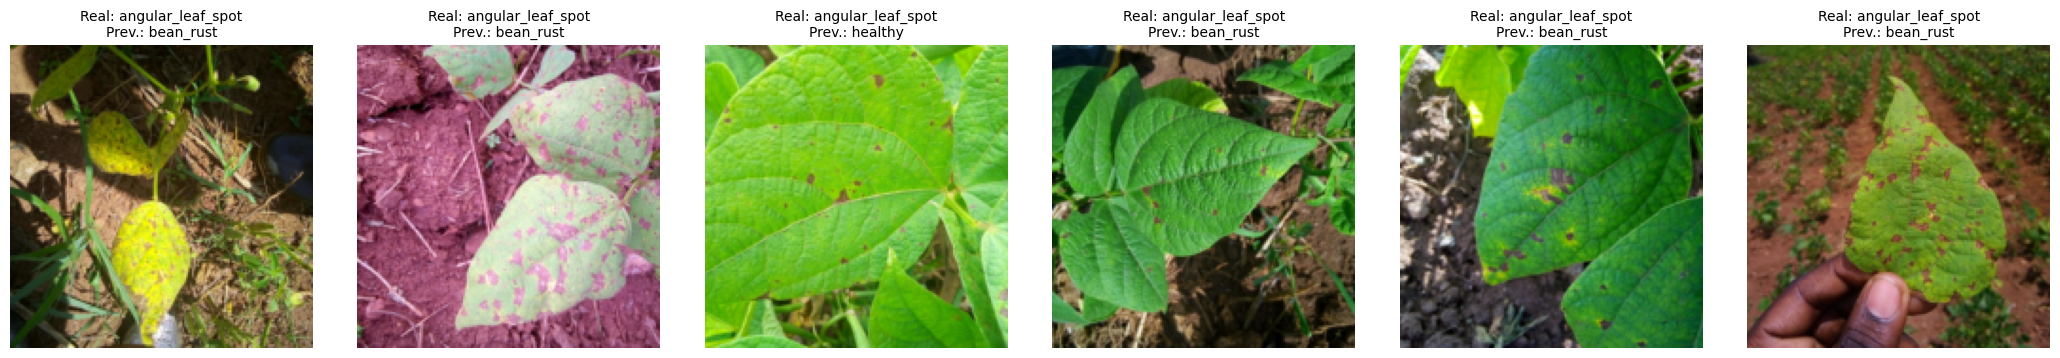

In [16]:
# Mostre erros sem selecionar manualmente imagens que confirmem uma narrativa.
rotulos_validacao, previsoes_cnn_basico, probabilidades_cnn_basico = coletar_previsoes(
    modelo_cnn_basico, dados_validacao
)
indices_erros = np.flatnonzero(rotulos_validacao != previsoes_cnn_basico)
print('Total de erros na validação:', len(indices_erros))

if len(indices_erros) == 0:
    print('Nenhum erro na validação. Reavalie a possibilidade de sobreajuste e confira a auditoria.')
else:
    indices_exibidos = set(indices_erros[:6].tolist())
    imagens_para_inspecao = {}
    for indice, (imagem, rotulo) in enumerate(dados_validacao.unbatch()):
        if indice in indices_exibidos:
            imagens_para_inspecao[indice] = imagem.numpy()
        if len(imagens_para_inspecao) == len(indices_exibidos):
            break
    figura, eixos = plt.subplots(1, len(indices_exibidos),
                                figsize=(3.5 * len(indices_exibidos), 3.5), squeeze=False)
    for eixo, indice in zip(eixos[0], sorted(indices_exibidos)):
        eixo.imshow(np.clip(imagens_para_inspecao[indice] / 255.0, 0, 1))
        eixo.set_title(f'Real: {nomes_classes[rotulos_validacao[indice]]}\n'
                       f'Prev.: {nomes_classes[previsoes_cnn_basico[indice]]}', fontsize=10)
        eixo.axis('off')
    plt.tight_layout()
    plt.show()

**Discussão:** uma fotografia pode ter manchas pouco nítidas, folha recortada ou iluminação diferente. Esses fatores são hipóteses sobre erros; **não** basta observar meia dúzia de fotos para demonstrar que uma dessas características causou a falha.

O próximo passo não será aumentar indiscriminadamente o modelo. Primeiro tentaremos **regularizar** o treinamento.

## 6. Experimento 3: EarlyStopping, Dropout e L2

**Pergunta:** como evitar que o modelo se ajuste demais às imagens de treinamento?

- **EarlyStopping:** acompanha `val_loss`, interrompe após um período sem melhora e restaura os melhores pesos.
- **Dropout:** zera aleatoriamente parte das ativações **durante o treino**; não apaga pesos.
- **L2:** adiciona um termo à função objetivo que penaliza pesos grandes (aqui, na camada final).

Treinaremos primeiro a **mesma arquitetura com EarlyStopping**, para isolar seu efeito. Depois treinaremos uma **nova CNN com Dropout e L2**. Essa segunda comparação altera *duas coisas simultaneamente*; não identifica o efeito de cada uma isoladamente.

Epoch 1/25


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


33/33 - 65s - 2s/step - acuracia: 0.4139 - loss: 1.0650 - val_acuracia: 0.4511 - val_loss: 0.9768
Epoch 2/25
33/33 - 84s - 3s/step - acuracia: 0.5397 - loss: 0.9655 - val_acuracia: 0.4211 - val_loss: 0.9367
Epoch 3/25
33/33 - 82s - 2s/step - acuracia: 0.5735 - loss: 0.9147 - val_acuracia: 0.6391 - val_loss: 0.8596
Epoch 4/25
33/33 - 64s - 2s/step - acuracia: 0.5880 - loss: 0.8828 - val_acuracia: 0.6692 - val_loss: 0.8346
Epoch 5/25
33/33 - 63s - 2s/step - acuracia: 0.6248 - loss: 0.8582 - val_acuracia: 0.6992 - val_loss: 0.7676
Epoch 6/25
33/33 - 82s - 2s/step - acuracia: 0.6644 - loss: 0.7801 - val_acuracia: 0.5714 - val_loss: 0.9656
Epoch 7/25
33/33 - 63s - 2s/step - acuracia: 0.6219 - loss: 0.8395 - val_acuracia: 0.6466 - val_loss: 0.7721
Epoch 8/25
33/33 - 81s - 2s/step - acuracia: 0.6402 - loss: 0.7974 - val_acuracia: 0.6842 - val_loss: 0.7537
Epoch 9/25
33/33 - 64s - 2s/step - acuracia: 0.6789 - loss: 0.7486 - val_acuracia: 0.6541 - val_loss: 0.6749
Epoch 10/25
33/33 - 82s - 2s/s

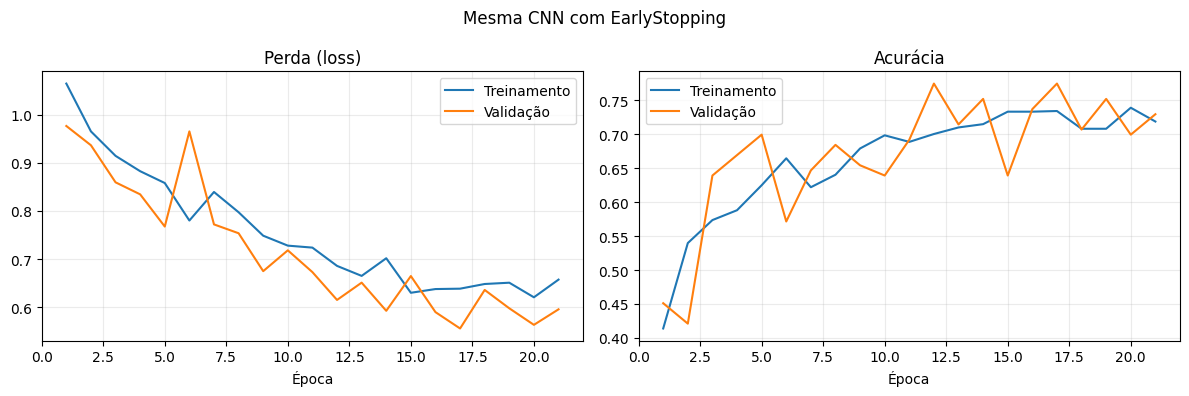

CNN + EarlyStopping: acurácia de validação = 77.4%; F1 macro = 0.775


In [17]:
tf.keras.utils.set_random_seed(SEMENTE_ALEATORIA)
modelo_cnn_parada_antecipada = construir_cnn()
compilar_modelo(modelo_cnn_parada_antecipada, taxa_aprendizado=1e-3)

inicio_treinamento = time.perf_counter()
historico_cnn_parada = modelo_cnn_parada_antecipada.fit(
    dados_treinamento, validation_data=dados_validacao,
    epochs=EPOCAS_CNN_INICIAL, callbacks=criar_callbacks(paciencia=4),
    verbose=2,
)
tempo_cnn_parada = time.perf_counter() - inicio_treinamento
plotar_curvas_treinamento(historico_cnn_parada, 'Mesma CNN com EarlyStopping')
registrar_experimento('CNN + EarlyStopping', modelo_cnn_parada_antecipada,
                      tempo_cnn_parada, len(historico_cnn_parada.history['loss']))

Epoch 1/25


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


33/33 - 65s - 2s/step - acuracia: 0.4420 - loss: 1.0686 - val_acuracia: 0.6466 - val_loss: 0.9476
Epoch 2/25
33/33 - 82s - 2s/step - acuracia: 0.5474 - loss: 0.9603 - val_acuracia: 0.6015 - val_loss: 0.8782
Epoch 3/25
33/33 - 63s - 2s/step - acuracia: 0.5629 - loss: 0.9267 - val_acuracia: 0.6316 - val_loss: 0.8856
Epoch 4/25
33/33 - 82s - 2s/step - acuracia: 0.5938 - loss: 0.8982 - val_acuracia: 0.6165 - val_loss: 0.8368
Epoch 5/25
33/33 - 63s - 2s/step - acuracia: 0.6190 - loss: 0.8682 - val_acuracia: 0.5639 - val_loss: 0.8521
Epoch 6/25
33/33 - 64s - 2s/step - acuracia: 0.6035 - loss: 0.8852 - val_acuracia: 0.5940 - val_loss: 0.9002
Epoch 7/25
33/33 - 82s - 2s/step - acuracia: 0.6499 - loss: 0.8343 - val_acuracia: 0.6992 - val_loss: 0.7515
Epoch 8/25
33/33 - 64s - 2s/step - acuracia: 0.6586 - loss: 0.7936 - val_acuracia: 0.6767 - val_loss: 0.7191
Epoch 9/25
33/33 - 82s - 2s/step - acuracia: 0.6818 - loss: 0.7823 - val_acuracia: 0.6992 - val_loss: 0.6947
Epoch 10/25
33/33 - 64s - 2s/s

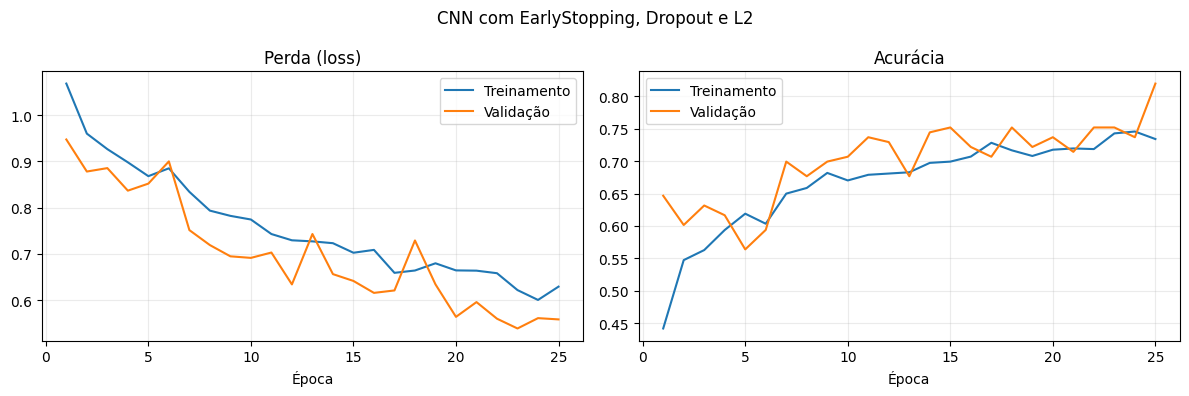

CNN regularizada: acurácia de validação = 75.2%; F1 macro = 0.754


In [18]:
tf.keras.utils.set_random_seed(SEMENTE_ALEATORIA)
modelo_cnn_regularizado = construir_cnn(
    usar_dropout=True, usar_regularizacao_l2=True,
    taxa_dropout=0.3, intensidade_l2=1e-4,
)
compilar_modelo(modelo_cnn_regularizado, taxa_aprendizado=1e-3)

inicio_treinamento = time.perf_counter()
historico_cnn_regularizado = modelo_cnn_regularizado.fit(
    dados_treinamento, validation_data=dados_validacao,
    epochs=EPOCAS_MODELOS_REGULARIZADOS,
    callbacks=criar_callbacks(paciencia=4), verbose=2,
)
tempo_cnn_regularizado = time.perf_counter() - inicio_treinamento
plotar_curvas_treinamento(historico_cnn_regularizado,
                          'CNN com EarlyStopping, Dropout e L2')
registrar_experimento('CNN regularizada', modelo_cnn_regularizado,
                      tempo_cnn_regularizado,
                      len(historico_cnn_regularizado.history['loss']))

### Atenção ao comparar losses!

A `loss` de um modelo com L2 pode incluir **perda de classificação + penalização**, enquanto a loss do modelo sem L2 contém só a primeira. Por isso, comparar diretamente suas `val_loss` não é comparar a mesma função numérica. Usaremos **acurácia e F1 macro na mesma validação** para comparar desempenho preditivo.

**Experimento opcional:** criar quatro versões com condições idênticas: (a) sem Dropout nem L2; (b) apenas Dropout; (c) apenas L2; (d) ambos. Isso seria uma *ablação*, necessária para separar os efeitos de cada regularizador.

In [19]:
colunas_resumo = ['modelo', 'acuracia', 'f1_macro', 'epocas',
                  'tempo_segundos', 'parametros_treinaveis']
display(pd.DataFrame(resultados_experimentos.values())[colunas_resumo].round(3))

,modelo,acuracia,f1_macro,epocas,tempo_segundos,parametros_treinaveis
0,CNN básica,0.767,0.764,25,1873.8,93635
1,CNN + EarlyStopping,0.774,0.775,21,1624.3,93635
2,CNN regularizada,0.752,0.754,25,1845.7,93635


## 7. Experimento 4: Data augmentation

**Pergunta:** a CNN melhora se aprender com pequenas variações plausíveis das fotos de treinamento?

Aplicaremos: espelhamento horizontal, rotações próximas de ±15° e zoom moderado (até 10%). **Não introduziremos grandes alterações nas cores das folhas**, pois descoloração pode ser um sintoma relevante da doença.

**Regra contra vazamento:** as transformações aleatórias ficam em camadas Keras dentro do modelo e atuam durante `fit()`. Na validação e no teste, não são aplicadas. Não criaremos fotos aumentadas para redistribuí-las pelos splits.

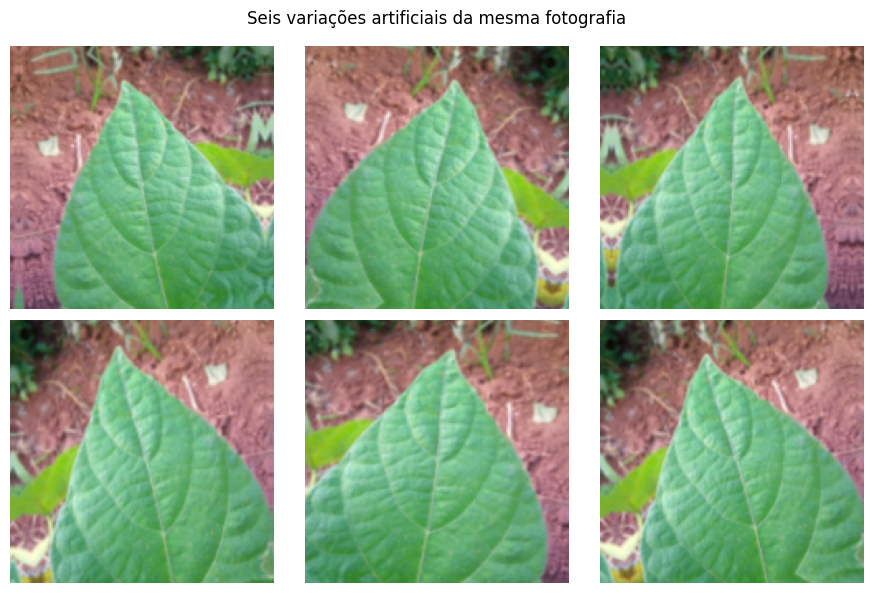

In [20]:
def construir_aumentacao():
    return keras.Sequential([
        layers.RandomFlip('horizontal'),
        layers.RandomRotation(factor=15 / 360.0, fill_mode='reflect'),
        layers.RandomZoom(height_factor=0.1, width_factor=0.1,
                          fill_mode='reflect'),
    ], name='aumentacao_treinamento')

# A mesma foto, seis resultados de uma transformação aleatória.
imagem_para_aumentar, _ = next(iter(dados_treinamento.unbatch()))
camada_aumentacao_demo = construir_aumentacao()
figura, eixos = plt.subplots(2, 3, figsize=(9, 6))
for eixo in eixos.flat:
    imagem_transformada = camada_aumentacao_demo(
        tf.expand_dims(imagem_para_aumentar, axis=0), training=True
    )[0].numpy()
    eixo.imshow(np.clip(imagem_transformada / 255.0, 0, 1))
    eixo.axis('off')
figura.suptitle('Seis variações artificiais da mesma fotografia')
plt.tight_layout()
plt.show()

O rótulo da folha deveria mudar depois de uma pequena rotação? E se alterássemos radicalmente a cor dos sintomas? Quais transformações parecem razoáveis nesse domínio?

Agora isolamos **uma mudança** em relação ao modelo regularizado: a inserção de aumentação. A arquitetura de classificação, a loss e os demais hiperparâmetros permanecem iguais.

Epoch 1/25


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


33/33 - 70s - 2s/step - acuracia: 0.4323 - loss: 1.0780 - val_acuracia: 0.5113 - val_loss: 1.0097
Epoch 2/25
33/33 - 68s - 2s/step - acuracia: 0.5280 - loss: 0.9857 - val_acuracia: 0.5263 - val_loss: 0.9365
Epoch 3/25
33/33 - 68s - 2s/step - acuracia: 0.5909 - loss: 0.9171 - val_acuracia: 0.5639 - val_loss: 0.8673
Epoch 4/25
33/33 - 69s - 2s/step - acuracia: 0.5822 - loss: 0.9091 - val_acuracia: 0.5489 - val_loss: 0.8942
Epoch 5/25
33/33 - 82s - 2s/step - acuracia: 0.6006 - loss: 0.8804 - val_acuracia: 0.6617 - val_loss: 0.8405
Epoch 6/25
33/33 - 82s - 2s/step - acuracia: 0.6277 - loss: 0.8380 - val_acuracia: 0.6842 - val_loss: 0.7871
Epoch 7/25
33/33 - 68s - 2s/step - acuracia: 0.6431 - loss: 0.8281 - val_acuracia: 0.6617 - val_loss: 0.7731
Epoch 8/25
33/33 - 68s - 2s/step - acuracia: 0.6586 - loss: 0.7833 - val_acuracia: 0.6767 - val_loss: 0.8579
Epoch 9/25
33/33 - 68s - 2s/step - acuracia: 0.6625 - loss: 0.7944 - val_acuracia: 0.7068 - val_loss: 0.7209
Epoch 10/25
33/33 - 68s - 2s/s

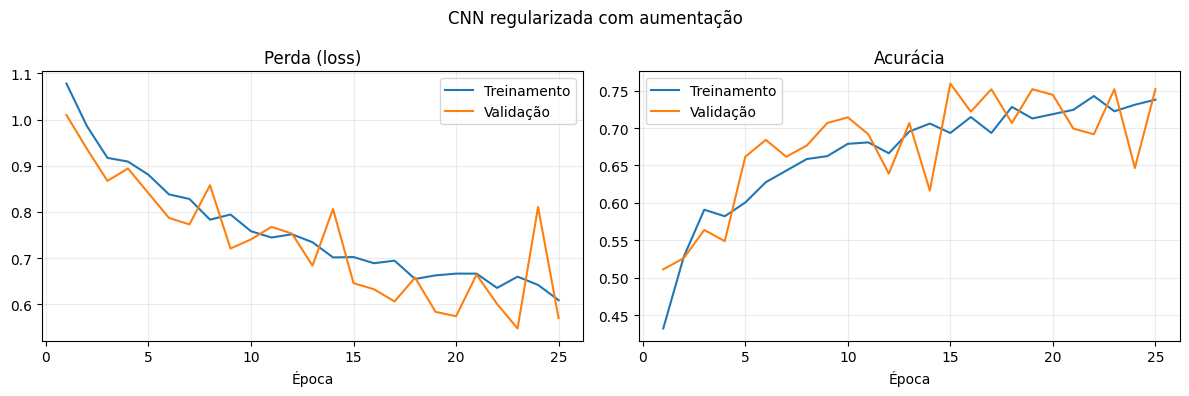

CNN + aumentação: acurácia de validação = 75.2%; F1 macro = 0.750


In [21]:
tf.keras.utils.set_random_seed(SEMENTE_ALEATORIA)
modelo_cnn_aumentado = construir_cnn(
    usar_dropout=True,
    usar_regularizacao_l2=True,
    camada_aumentacao=construir_aumentacao(),
)
compilar_modelo(modelo_cnn_aumentado, taxa_aprendizado=1e-3)

inicio_treinamento = time.perf_counter()
historico_cnn_aumentado = modelo_cnn_aumentado.fit(
    dados_treinamento, validation_data=dados_validacao,
    epochs=EPOCAS_MODELOS_REGULARIZADOS,
    callbacks=criar_callbacks(paciencia=4), verbose=2,
)
tempo_cnn_aumentado = time.perf_counter() - inicio_treinamento
plotar_curvas_treinamento(historico_cnn_aumentado,
                          'CNN regularizada com aumentação')
registrar_experimento('CNN + aumentação', modelo_cnn_aumentado,
                      tempo_cnn_aumentado,
                      len(historico_cnn_aumentado.history['loss']))

**Interpretação obrigatória:** houve melhora na validação? Se não houve, isso prova que aumentação "não funciona"? Não: resultado depende de arquitetura, transformações, dados e aleatoriedade. **As fotos aumentadas não são novas observações independentes.**

## 8. Experimento 5: Transfer learning com MobileNetV2

**Pergunta:** por que aprender todos os filtros desde o início se podemos reutilizar filtros treinados anteriormente com muitas imagens?

A **MobileNetV2** vem pré-treinada no ImageNet. Removeremos a saída original (`include_top=False`) e adicionaremos a nossa classificação de três classes. Na primeira fase, **todos os pesos da base ficam congelados**.

**Pré-processamento:** imagens de entrada continuam em 0–255, mas a MobileNetV2 exige uma transformação equivalente a `pixel / 127.5 - 1` (faixa [-1,1]). Faremos isso **dentro da arquitetura**. Não aplicaremos também `Rescaling(1/255)`.

A função abaixo constrói **dois modelos que compartilham as mesmas camadas e pesos**: o classificador usual e um auxiliar que devolve os mapas convolucionais finais + logits. O auxiliar será útil mais adiante para calcular o Grad-CAM sem precisar acessar camadas aninhadas por nome.

In [22]:
def construir_modelo_transferencia():
    base_mobilenet = keras.applications.MobileNetV2(
        input_shape=(ALTURA_IMAGEM, LARGURA_IMAGEM, 3),
        include_top=False,
        weights='imagenet',
    )
    base_mobilenet.trainable = False

    entrada_imagem = keras.Input(
        shape=(ALTURA_IMAGEM, LARGURA_IMAGEM, 3), name='imagem_rgb'
    )
    imagem_aumentada = construir_aumentacao()(entrada_imagem)
    imagem_preprocessada = layers.Rescaling(
        scale=1.0 / 127.5, offset=-1.0, name='preprocessar_mobilenet'
    )(imagem_aumentada)
    # training=False mantém BatchNormalization em modo de inferência,
    # inclusive na fase posterior de fine-tuning.
    mapas_caracteristicas = base_mobilenet(imagem_preprocessada, training=False)
    caracteristicas = layers.GlobalAveragePooling2D()(mapas_caracteristicas)
    caracteristicas = layers.Dropout(0.2)(caracteristicas)
    logits_classes = layers.Dense(numero_classes, name='logits_classes')(caracteristicas)

    modelo_classificacao = keras.Model(
        entrada_imagem, logits_classes, name='classificador_mobilenet'
    )
    extrator_gradcam = keras.Model(
        entrada_imagem, [mapas_caracteristicas, logits_classes],
        name='extrator_gradcam_mobilenet',
    )
    return modelo_classificacao, base_mobilenet, extrator_gradcam


tf.keras.utils.set_random_seed(SEMENTE_ALEATORIA)
modelo_transferencia, base_mobilenet, extrator_gradcam_transferencia = (
    construir_modelo_transferencia()
)
compilar_modelo(modelo_transferencia, taxa_aprendizado=1e-3)
modelo_transferencia.summary()
print('Parâmetros treináveis:', contar_parametros_treinaveis(modelo_transferencia))
print('Parâmetros NÃO treináveis:',
      int(sum(np.prod(peso.shape) for peso in modelo_transferencia.non_trainable_weights)))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "classificador_mobilenet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagem_rgb (InputLayer)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumentacao_treinamento          │ (None, 160, 160, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocessar_mobilenet          │ (None, 160, 160, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits_classes (Dense)          │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Parâmetros treináveis: 3843
Parâmetros NÃO treináveis: 2257984


Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


33/33 - 38s - 1s/step - acuracia: 0.5716 - loss: 0.8991 - val_acuracia: 0.7594 - val_loss: 0.6059
Epoch 2/20
33/33 - 33s - 1s/step - acuracia: 0.7834 - loss: 0.5387 - val_acuracia: 0.8045 - val_loss: 0.4490
Epoch 3/20
33/33 - 40s - 1s/step - acuracia: 0.8240 - loss: 0.4268 - val_acuracia: 0.8421 - val_loss: 0.4259
Epoch 4/20
33/33 - 40s - 1s/step - acuracia: 0.8491 - loss: 0.3757 - val_acuracia: 0.8647 - val_loss: 0.3841
Epoch 5/20
33/33 - 32s - 984ms/step - acuracia: 0.8627 - loss: 0.3618 - val_acuracia: 0.8647 - val_loss: 0.3495
Epoch 6/20
33/33 - 33s - 996ms/step - acuracia: 0.8752 - loss: 0.3145 - val_acuracia: 0.8647 - val_loss: 0.3260
Epoch 7/20
33/33 - 41s - 1s/step - acuracia: 0.8859 - loss: 0.2867 - val_acuracia: 0.8571 - val_loss: 0.3668
Epoch 8/20
33/33 - 33s - 1s/step - acuracia: 0.8965 - loss: 0.2704 - val_acuracia: 0.8797 - val_loss: 0.3208
Epoch 9/20
33/33 - 41s - 1s/step - acuracia: 0.8985 - loss: 0.2845 - val_acuracia: 0.8722 - val_loss: 0.3357
Epoch 10/20
33/33 - 32s 

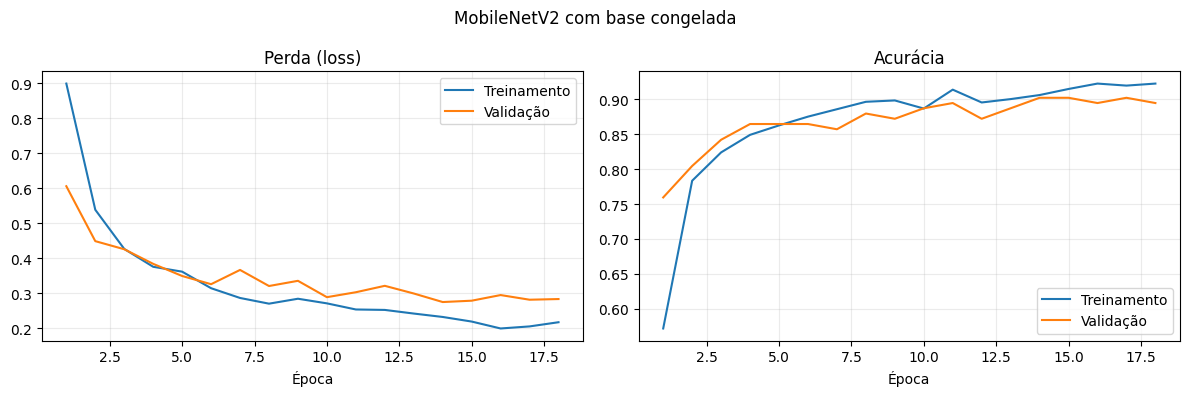

MobileNetV2 congelada: acurácia de validação = 90.2%; F1 macro = 0.904


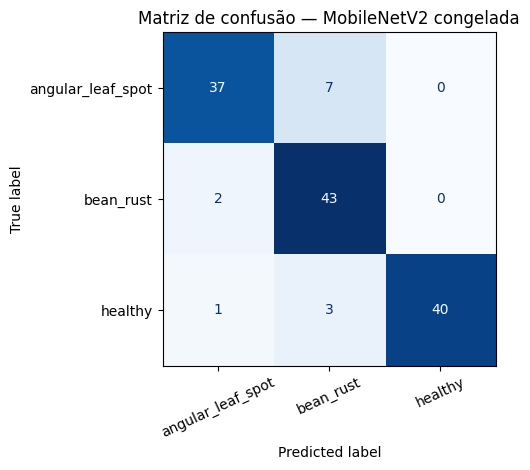

In [23]:
inicio_treinamento = time.perf_counter()
historico_transferencia = modelo_transferencia.fit(
    dados_treinamento, validation_data=dados_validacao,
    epochs=EPOCAS_TRANSFERENCIA,
    callbacks=criar_callbacks(paciencia=4), verbose=2,
)
tempo_transferencia = time.perf_counter() - inicio_treinamento
plotar_curvas_treinamento(historico_transferencia, 'MobileNetV2 com base congelada')
registrar_experimento('MobileNetV2 congelada', modelo_transferencia,
                      tempo_transferencia, len(historico_transferencia.history['loss']))
_ = avaliar_classificacao(modelo_transferencia, dados_validacao,
                          titulo='MobileNetV2 congelada')

**Perguntas:** quantos parâmetros foram treinados? A transferência trouxe ganho em relação à CNN com aumentação? E quanto tempo custou? Uma rede maior nem sempre é a melhor escolha para um projeto pequeno ou para inferência em celular.

Vamos preservar o modelo congelado como referência e treinar **uma cópia independente** durante o ajuste fino. Assim, continuar comparando os dois modelos será possível.

## 9. Experimento 6: Fine-tuning

**Pergunta:** depois de treinar a nova saída, adaptar algumas camadas convolucionais finais melhora a validação?

Procedimento:

1. Criar uma segunda instância da mesma arquitetura e copiar os pesos **já treinados** do classificador congelado.
2. Descongelar somente parte das camadas finais da base.
3. Manter `BatchNormalization` congelada e a chamada da base com `training=False`.
4. **Recompilar** (as camadas treináveis mudaram) com taxa de aprendizado muito menor (`1e-5`).
5. Comparar a validação. **Fine-tuning não é garantia de melhora**.

In [24]:
# Modelo independente: a rede congelada original permanece intacta.
tf.keras.utils.set_random_seed(SEMENTE_ALEATORIA)
modelo_ajuste_fino, base_ajuste_fino, extrator_gradcam_ajuste_fino = (
    construir_modelo_transferencia()
)
modelo_ajuste_fino.set_weights(modelo_transferencia.get_weights())

base_ajuste_fino.trainable = True
QUANTIDADE_CAMADAS_FINAIS = 20  # escolha experimental, não valor universal
for camada in base_ajuste_fino.layers[:-QUANTIDADE_CAMADAS_FINAIS]:
    camada.trainable = False
for camada in base_ajuste_fino.layers:
    if isinstance(camada, layers.BatchNormalization):
        camada.trainable = False

compilar_modelo(modelo_ajuste_fino, taxa_aprendizado=1e-5)
print('Antes: base congelada:', contar_parametros_treinaveis(modelo_transferencia))
print('Depois: ajuste fino:', contar_parametros_treinaveis(modelo_ajuste_fino))
assert contar_parametros_treinaveis(modelo_ajuste_fino) > contar_parametros_treinaveis(modelo_transferencia)

Antes: base congelada: 3843
Depois: ajuste fino: 1198723


Epoch 1/12


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


33/33 - 48s - 1s/step - acuracia: 0.9159 - loss: 0.2137 - val_acuracia: 0.8797 - val_loss: 0.2937
Epoch 2/12
33/33 - 39s - 1s/step - acuracia: 0.9255 - loss: 0.2023 - val_acuracia: 0.9098 - val_loss: 0.2605
Epoch 3/12
33/33 - 41s - 1s/step - acuracia: 0.9381 - loss: 0.1720 - val_acuracia: 0.9173 - val_loss: 0.2289
Epoch 4/12
33/33 - 39s - 1s/step - acuracia: 0.9342 - loss: 0.1685 - val_acuracia: 0.9098 - val_loss: 0.2717
Epoch 5/12
33/33 - 39s - 1s/step - acuracia: 0.9323 - loss: 0.1619 - val_acuracia: 0.9098 - val_loss: 0.2480
Epoch 6/12
33/33 - 39s - 1s/step - acuracia: 0.9458 - loss: 0.1427 - val_acuracia: 0.9173 - val_loss: 0.2690


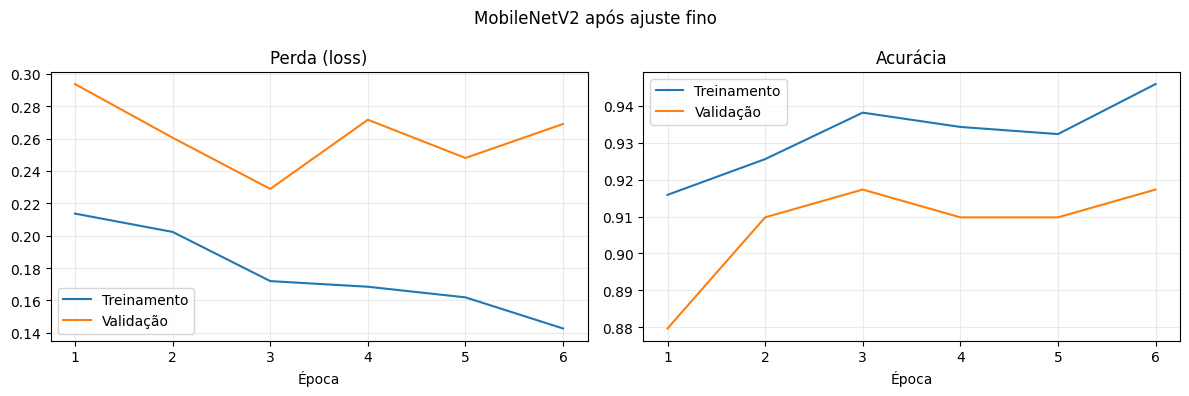

MobileNetV2 fine-tuning: acurácia de validação = 91.7%; F1 macro = 0.918


In [25]:
inicio_treinamento = time.perf_counter()
historico_ajuste_fino = modelo_ajuste_fino.fit(
    dados_treinamento, validation_data=dados_validacao,
    epochs=EPOCAS_AJUSTE_FINO,
    callbacks=criar_callbacks(paciencia=3), verbose=2,
)
tempo_ajuste_fino = time.perf_counter() - inicio_treinamento
plotar_curvas_treinamento(historico_ajuste_fino, 'MobileNetV2 após ajuste fino')
registrar_experimento('MobileNetV2 fine-tuning', modelo_ajuste_fino,
                      tempo_transferencia + tempo_ajuste_fino,
                      len(historico_transferencia.history['loss'])
                      + len(historico_ajuste_fino.history['loss']))

In [26]:
resultado_base_congelada = resultados_experimentos['MobileNetV2 congelada']
resultado_base_ajustada = resultados_experimentos['MobileNetV2 fine-tuning']
print('Acurácia com base congelada:', f"{resultado_base_congelada['acuracia']:.1%}")
print('Acurácia após ajuste fino:', f"{resultado_base_ajustada['acuracia']:.1%}")
print('Diferença (pontos percentuais):',
      round(100 * (resultado_base_ajustada['acuracia']
                   - resultado_base_congelada['acuracia']), 2))
print('Tempo adicional do ajuste fino (segundos):', round(tempo_ajuste_fino, 1))

Acurácia com base congelada: 90.2%
Acurácia após ajuste fino: 91.7%
Diferença (pontos percentuais): 1.5
Tempo adicional do ajuste fino (segundos): 245.6


**Interpretação:** uma diferença de um ou dois acertos em apenas 133 fotografias de validação não é evidência forte de superioridade. Qual configuração você manteria considerando estabilidade, custo e desempenho? O teste **ainda não deve ser utilizado**.

## 10. Experimento 7: Grad-CAM: onde há pistas para cada classe?

**Pergunta:** uma fotografia foi classificada como ferrugem. Quais regiões receberam **atribuição positiva** para a pontuação dessa classe?

O Grad-CAM é uma técnica de explicação local: combina **mapas de características** de uma camada convolucional com os **gradientes do logit** de uma classe. Em seguida, obtemos um mapa de calor sobreposto à fotografia. Ele **não** é segmentação, probabilidade por pixel nem prova de causalidade.

Vamos usar a **MobileNetV2 de melhor validação** entre congelada e ajustada. Uma comparação de Grad-CAM usa sempre a classe especificada. O mapa para `bean_rust` pode ser diferente do mapa para `healthy` na mesma fotografia.

In [27]:
# A escolha do modelo depende somente da VALIDAÇÃO, jamais do TESTE.
if (resultado_base_ajustada['f1_macro'] > resultado_base_congelada['f1_macro']):
    modelo_para_gradcam = modelo_ajuste_fino
    extrator_para_gradcam = extrator_gradcam_ajuste_fino
    nome_modelo_gradcam = 'MobileNetV2 fine-tuning'
else:
    modelo_para_gradcam = modelo_transferencia
    extrator_para_gradcam = extrator_gradcam_transferencia
    nome_modelo_gradcam = 'MobileNetV2 congelada'
print('Modelo para Grad-CAM (escolhido pela validação):', nome_modelo_gradcam)


def gerar_gradcam(extrator, imagem, indice_classe):
    """Grad-CAM no mapa final da MobileNetV2, relativo a um logit especificado.

    imagem: Tensor [altura, largura, 3] em 0..255.
    indice_classe: índice inteiro de 0 a numero_classes-1.
    Retorna: mapa normalizado [altura_da_base, largura_da_base], em 0..1.
    """
    indice_classe = int(indice_classe)
    if not 0 <= indice_classe < numero_classes:
        raise ValueError('Índice de classe inválido.')
    imagens_lote = tf.expand_dims(tf.convert_to_tensor(imagem, dtype=tf.float32), 0)

    with tf.GradientTape() as fita_gradientes:
        # Observamos a imagem para calcular gradientes mesmo com a base congelada.
        fita_gradientes.watch(imagens_lote)
        mapas_caracteristicas, logits = extrator(imagens_lote, training=False)
        logit_classe = logits[:, indice_classe]

    gradientes = fita_gradientes.gradient(logit_classe, mapas_caracteristicas)
    if gradientes is None:
        raise RuntimeError('Gradientes ausentes; confira a conexão entre mapas e logits.')

    pesos_canais = tf.reduce_mean(gradientes[0], axis=(0, 1))
    mapa = tf.reduce_sum(mapas_caracteristicas[0] * pesos_canais, axis=-1)
    mapa = tf.nn.relu(mapa)   # destaca atribuição positiva
    valor_maximo = tf.reduce_max(mapa)
    mapa = tf.where(valor_maximo > 0, mapa / (valor_maximo + 1e-8),
                    tf.zeros_like(mapa))
    return mapa.numpy()


def sobrepor_gradcam(imagem, mapa_gradcam, intensidade=0.45):
    """Sobreposição para visualização; cores NÃO são probabilidades por pixel."""
    imagem_numpy = np.asarray(imagem, dtype=np.float32)
    imagem_normalizada = np.clip(imagem_numpy / 255.0, 0.0, 1.0)
    mapa_ampliado = tf.image.resize(
        mapa_gradcam[..., np.newaxis], [ALTURA_IMAGEM, LARGURA_IMAGEM]
    ).numpy()[..., 0]
    # Cores do mapa: colormap de matplotlib; é somente representação visual.
    cores_mapa = plt.get_cmap('jet')(np.clip(mapa_ampliado, 0, 1))[..., :3]
    return (1 - intensidade) * imagem_normalizada + intensidade * cores_mapa

Modelo para Grad-CAM (escolhido pela validação): MobileNetV2 fine-tuning


### 10.1 Uma folha, várias pontuações

Selecionaremos **uma imagem do conjunto de validação**, preferencialmente com a classe `bean_rust` (ferrugem), sem usar o teste. A tabela mostra as probabilidades das três classes, mas **o Grad-CAM será calculado para um logit**, antes da softmax.

In [28]:
indice_classe_ferrugem = nomes_classes.index('bean_rust')
imagem_folha_gradcam = None
rotulo_folha_gradcam = None
for imagem, rotulo in dados_validacao.unbatch():
    if int(rotulo) == indice_classe_ferrugem:
        imagem_folha_gradcam = imagem.numpy()
        rotulo_folha_gradcam = int(rotulo)
        break
assert imagem_folha_gradcam is not None

logits_folha = modelo_para_gradcam(
    tf.expand_dims(imagem_folha_gradcam, 0), training=False
)[0]
probabilidades_folha = tf.nn.softmax(logits_folha).numpy()
indice_classe_prevista = int(np.argmax(probabilidades_folha))

display(pd.DataFrame({
    'classe': nomes_classes,
    'probabilidade_softmax': probabilidades_folha,
}).sort_values('probabilidade_softmax', ascending=False).round(4))
print('Rótulo verdadeiro:', nomes_classes[rotulo_folha_gradcam])
print('Classe prevista:', nomes_classes[indice_classe_prevista])

,classe,probabilidade_softmax
1,bean_rust,0.9630
2,healthy,0.0356
0,angular_leaf_spot,0.0013


Rótulo verdadeiro: bean_rust
Classe prevista: bean_rust


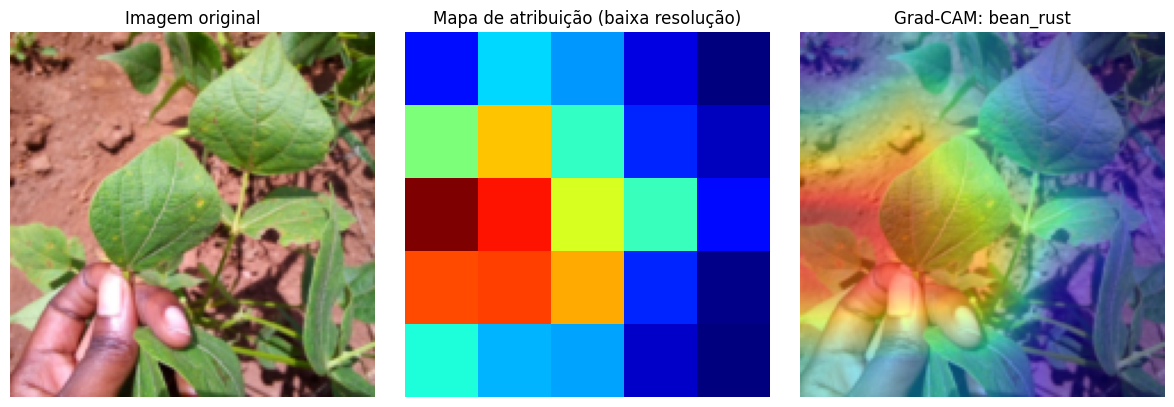

In [29]:
mapa_classe_prevista = gerar_gradcam(
    extrator_para_gradcam, imagem_folha_gradcam, indice_classe_prevista
)

figura, eixos = plt.subplots(1, 3, figsize=(12, 4))
eixos[0].imshow(np.clip(imagem_folha_gradcam / 255.0, 0, 1))
eixos[0].set_title('Imagem original')
eixos[1].imshow(mapa_classe_prevista, cmap='jet', vmin=0, vmax=1)
eixos[1].set_title('Mapa de atribuição (baixa resolução)')
eixos[2].imshow(sobrepor_gradcam(imagem_folha_gradcam, mapa_classe_prevista))
eixos[2].set_title(f'Grad-CAM: {nomes_classes[indice_classe_prevista]}')
for eixo in eixos:
    eixo.axis('off')
plt.tight_layout()
plt.show()

### 10.2 Mudando apenas a classe investigada

A imagem e o modelo **não mudam**. Só alteraremos o índice da classe para a qual pedimos o mapa. Isso demonstra que Grad-CAM é uma **atribuição específica de classe**, não um detector universal da folha.

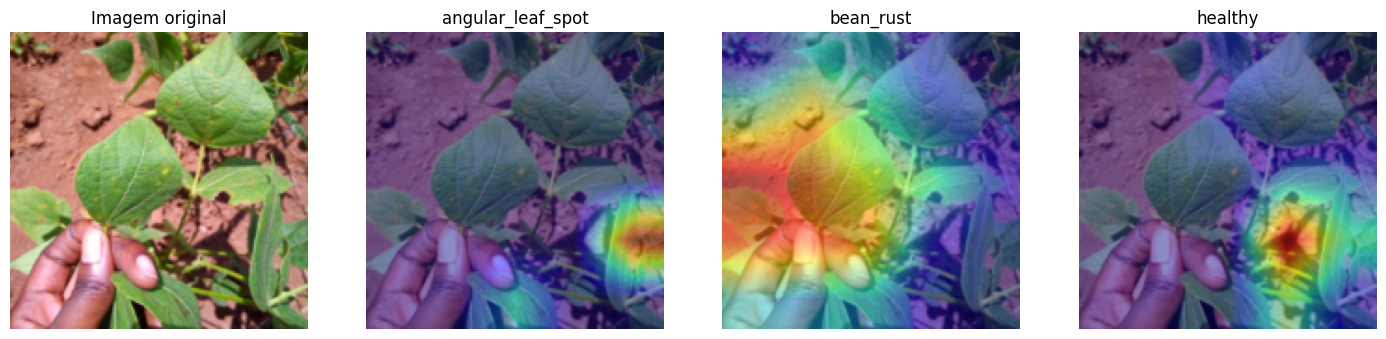

In [30]:
figura, eixos = plt.subplots(1, numero_classes + 1,
                            figsize=(3.6 * (numero_classes + 1), 3.4))
eixos[0].imshow(imagem_folha_gradcam / 255.0)
eixos[0].set_title('Imagem original')
eixos[0].axis('off')

for indice_classe in range(numero_classes):
    mapa = gerar_gradcam(extrator_para_gradcam, imagem_folha_gradcam, indice_classe)
    eixos[indice_classe + 1].imshow(sobrepor_gradcam(imagem_folha_gradcam, mapa))
    eixos[indice_classe + 1].set_title(nomes_classes[indice_classe])
    eixos[indice_classe + 1].axis('off')
plt.tight_layout()
plt.show()

### 10.3 E quando a previsão está errada?

Se houver pelo menos uma classificação incorreta na validação, mostraremos **dois mapas da mesma imagem**: um para a classe prevista e outro para o rótulo verdadeiro. Não atribua a diferença entre os mapas a uma causa única: eles ilustram a atribuição local e ajudam a formular hipóteses sobre a falha.

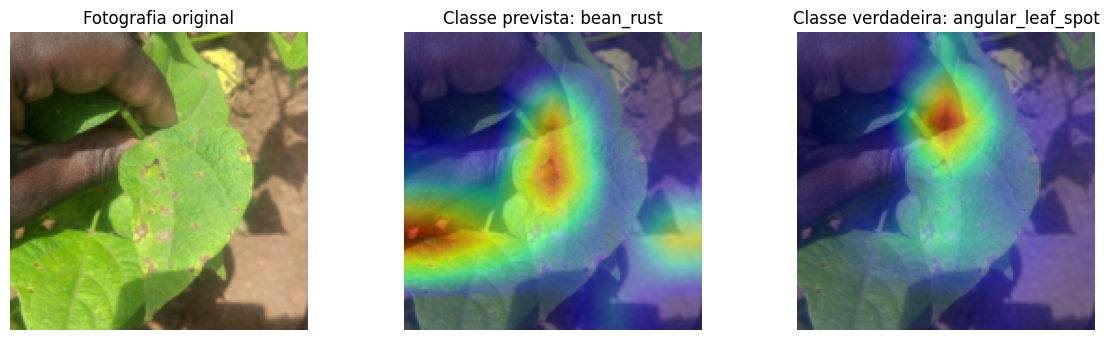

In [31]:
rotulos_gradcam, previsoes_gradcam, _ = coletar_previsoes(
    modelo_para_gradcam, dados_validacao
)
indices_erros_gradcam = np.flatnonzero(rotulos_gradcam != previsoes_gradcam)
if len(indices_erros_gradcam) == 0:
    print('Nenhuma previsão errada na validação: exemplo opcional não disponível.')
else:
    indice_erro = int(indices_erros_gradcam[0])
    imagem_errada = None
    for indice_imagem, (imagem, _) in enumerate(dados_validacao.unbatch()):
        if indice_imagem == indice_erro:
            imagem_errada = imagem.numpy()
            break

    indice_previsto = int(previsoes_gradcam[indice_erro])
    indice_verdadeiro = int(rotulos_gradcam[indice_erro])
    mapa_previsto = gerar_gradcam(extrator_para_gradcam, imagem_errada, indice_previsto)
    mapa_verdadeiro = gerar_gradcam(extrator_para_gradcam, imagem_errada, indice_verdadeiro)

    figura, eixos = plt.subplots(1, 3, figsize=(12, 3.5))
    eixos[0].imshow(imagem_errada / 255.0)
    eixos[0].set_title('Fotografia original')
    eixos[1].imshow(sobrepor_gradcam(imagem_errada, mapa_previsto))
    eixos[1].set_title(f'Classe prevista: {nomes_classes[indice_previsto]}')
    eixos[2].imshow(sobrepor_gradcam(imagem_errada, mapa_verdadeiro))
    eixos[2].set_title(f'Classe verdadeira: {nomes_classes[indice_verdadeiro]}')
    for eixo in eixos:
        eixo.axis('off')
    plt.tight_layout()
    plt.show()

### Questões para discutir Grad-CAM

1. O mapa para a classe prevista é igual ao mapa de outra classe?
2. Regiões destacadas coincidem com sintomas que você consegue observar? E quando não coincidem?
3. Se o mapa destaca a folha, isso **prova** que a CNN ignorou o fundo? **Não.** Um mapa não é uma explicação causal completa.
4. Que experimento poderíamos fazer para testar uma pista suspeita? **Alterar apenas essa pista e medir a mudança na previsão.**

O experimento seguinte constrói deliberadamente uma pista artificial para demonstrar a diferença entre **visualizar uma atribuição** e **testar a sensibilidade da previsão**.

## 11. Experimento 8: Shortcut learning: o quadrado colorido

**Pergunta:** e se colocarmos uma pista muito fácil, mas **sem qualquer relação biológica**, em cada imagem?

Vamos construir um cenário artificial:

- `angular_leaf_spot` recebe **quadrado vermelho**;
- `bean_rust` recebe **quadrado azul**;
- `healthy` recebe **quadrado verde**.

Os rótulos continuam sendo as doenças reais. A **cor do quadrado é inserida por nós** e corresponde perfeitamente ao rótulo no treinamento. A rede pode aprender a classificar pela cor em vez de analisar as manchas.

> **Importante:** este é um experimento de diagnóstico sobre *atalhos*. A versão marcada do conjunto de validação usa o rótulo verdadeiro para fabricar sua marca e **não** constitui uma avaliação realista do desempenho em produção. Não usaremos esse experimento para selecionar o modelo final do problema original.

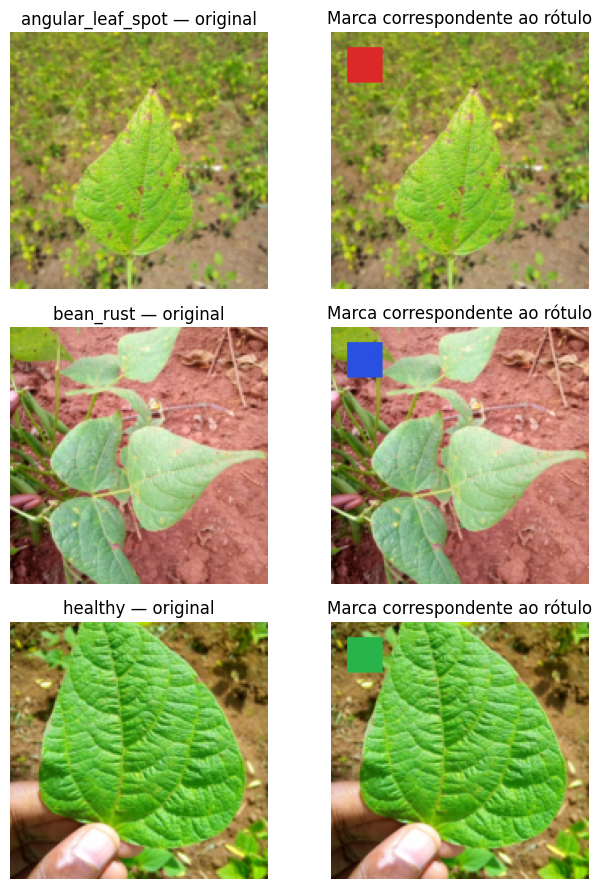

In [32]:
# A tabela é indexada conforme a ORDEM DE CLASSES devolvida pelo TFDS.
cores_quadrados_numpy = np.zeros((numero_classes, 3), dtype=np.float32)
cores_quadrados_numpy[nomes_classes.index('angular_leaf_spot')] = (220, 40, 40)
cores_quadrados_numpy[nomes_classes.index('bean_rust')] = (40, 80, 225)
cores_quadrados_numpy[nomes_classes.index('healthy')] = (40, 180, 75)
CORES_QUADRADOS = tf.constant(cores_quadrados_numpy, dtype=tf.float32)

TAMANHO_QUADRADO = 22
MARGEM_QUADRADO = 10


def inserir_quadrados_em_lote(imagens, rotulos, deslocamento_cor=0):
    """Insere marca em um lote RGB 0..255, SEM alterar pixels fora do quadrado.

    deslocamento_cor=0: cor corresponde ao rótulo.
    deslocamento_cor=1: cor é trocada ciclicamente por outra classe.
    """
    imagens = tf.convert_to_tensor(imagens, dtype=tf.float32)
    rotulos = tf.cast(rotulos, tf.int32)
    indices_cor = tf.math.floormod(rotulos + deslocamento_cor, numero_classes)
    cores_do_lote = tf.gather(CORES_QUADRADOS, indices_cor)

    margem_final_altura = ALTURA_IMAGEM - MARGEM_QUADRADO - TAMANHO_QUADRADO
    margem_final_largura = LARGURA_IMAGEM - MARGEM_QUADRADO - TAMANHO_QUADRADO
    mascara_quadrado = tf.pad(
        tf.ones((TAMANHO_QUADRADO, TAMANHO_QUADRADO, 1), dtype=tf.bool),
        [[MARGEM_QUADRADO, margem_final_altura],
         [MARGEM_QUADRADO, margem_final_largura], [0, 0]],
        constant_values=False,
    )
    mascara_quadrado = mascara_quadrado[tf.newaxis, ...]
    cores_expandida = cores_do_lote[:, tf.newaxis, tf.newaxis, :]
    return tf.where(mascara_quadrado, cores_expandida, imagens)


# Uma imagem original de cada classe e sua versão artificialmente marcada.
figura, eixos = plt.subplots(numero_classes, 2, figsize=(7, 3.0 * numero_classes))
exemplos_sem_marca = {}
for imagem, rotulo in dados_treinamento.unbatch():
    indice_classe = int(rotulo)
    if indice_classe not in exemplos_sem_marca:
        exemplos_sem_marca[indice_classe] = imagem.numpy()
    if len(exemplos_sem_marca) == numero_classes:
        break

for indice_classe in range(numero_classes):
    imagem_original = exemplos_sem_marca[indice_classe]
    imagem_marcada = inserir_quadrados_em_lote(
        imagem_original[None, ...],
        tf.constant([indice_classe]), deslocamento_cor=0
    )[0].numpy()
    eixos[indice_classe, 0].imshow(imagem_original / 255.0)
    eixos[indice_classe, 1].imshow(imagem_marcada / 255.0)
    eixos[indice_classe, 0].set_title(f'{nomes_classes[indice_classe]} — original')
    eixos[indice_classe, 1].set_title('Marca correspondente ao rótulo')
    for eixo in eixos[indice_classe]:
        eixo.axis('off')
plt.tight_layout()
plt.show()

### 11.1 Treinar a CNN com a pista presente

Treinaremos outra instância da **CNN pequena regularizada**, começando novamente com pesos aleatórios. Durante o treinamento, faremos aumentação **antes** de inserir o quadrado: isso evita que as rotações façam o quadrado desaparecer ou mudar de lugar. A marca ficará sempre no mesmo canto e com a mesma cor para cada classe.

Nenhum quadrado é inserido nas imagens originais do Beans: a transformação só ocorre no pipeline derivado e não modifica os splits armazenados.

In [33]:
camada_aumentacao_atalho = construir_aumentacao()


def aplicar_aumentacao_e_quadrado(imagens, rotulos):
    imagens_aumentadas = camada_aumentacao_atalho(imagens, training=True)
    imagens_marcadas = inserir_quadrados_em_lote(imagens_aumentadas, rotulos)
    return imagens_marcadas, rotulos


def construir_validacao_atalho(deslocamento_cor=None):
    if deslocamento_cor is None:
        return dados_validacao  # fotos originais, sem quadrado
    return dados_validacao.map(
        lambda imagens, rotulos: (
            inserir_quadrados_em_lote(imagens, rotulos,
                                      deslocamento_cor=deslocamento_cor),
            rotulos,
        ), num_parallel_calls=tf.data.AUTOTUNE,
    ).prefetch(tf.data.AUTOTUNE)


dados_treinamento_atalho = dados_treinamento.map(
    aplicar_aumentacao_e_quadrado, num_parallel_calls=tf.data.AUTOTUNE,
).prefetch(tf.data.AUTOTUNE)
dados_validacao_marca_correta = construir_validacao_atalho(deslocamento_cor=0)
dados_validacao_marca_trocada = construir_validacao_atalho(deslocamento_cor=1)
dados_validacao_sem_marca = construir_validacao_atalho(deslocamento_cor=None)

# Confere experimentalmente: ao trocar de cor, pixels FORA do quadrado são iguais.
lote_original, lote_rotulos = next(iter(dados_validacao))
com_cor_correta = inserir_quadrados_em_lote(lote_original, lote_rotulos, 0).numpy()
com_cor_trocada = inserir_quadrados_em_lote(lote_original, lote_rotulos, 1).numpy()
mascara_pixeis_diferentes = np.any(com_cor_correta != com_cor_trocada, axis=-1)
mascara_esperada = np.zeros((ALTURA_IMAGEM, LARGURA_IMAGEM), dtype=bool)
mascara_esperada[MARGEM_QUADRADO:MARGEM_QUADRADO + TAMANHO_QUADRADO,
                 MARGEM_QUADRADO:MARGEM_QUADRADO + TAMANHO_QUADRADO] = True
assert np.array_equal(mascara_pixeis_diferentes[0], mascara_esperada)
print('Verificado: a troca de cor altera somente os pixels do quadrado.')

Verificado: a troca de cor altera somente os pixels do quadrado.


Epoch 1/16


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


33/33 - 71s - 2s/step - acuracia: 0.4652 - loss: 1.0445 - val_acuracia: 0.5263 - val_loss: 0.9359
Epoch 2/16
33/33 - 84s - 3s/step - acuracia: 0.5793 - loss: 0.8999 - val_acuracia: 0.6617 - val_loss: 0.8587
Epoch 3/16
33/33 - 80s - 2s/step - acuracia: 0.6867 - loss: 0.7594 - val_acuracia: 0.8045 - val_loss: 0.5798
Epoch 4/16
33/33 - 82s - 2s/step - acuracia: 0.8685 - loss: 0.4781 - val_acuracia: 0.9624 - val_loss: 0.2235
Epoch 5/16
33/33 - 82s - 2s/step - acuracia: 0.9768 - loss: 0.1738 - val_acuracia: 1.0000 - val_loss: 0.0793
Epoch 6/16
33/33 - 70s - 2s/step - acuracia: 0.9923 - loss: 0.1028 - val_acuracia: 1.0000 - val_loss: 0.0278
Epoch 7/16
33/33 - 81s - 2s/step - acuracia: 0.9932 - loss: 0.0801 - val_acuracia: 1.0000 - val_loss: 0.0423
Epoch 8/16
33/33 - 69s - 2s/step - acuracia: 0.9952 - loss: 0.0508 - val_acuracia: 1.0000 - val_loss: 0.0211
Epoch 9/16
33/33 - 82s - 2s/step - acuracia: 0.9981 - loss: 0.0288 - val_acuracia: 1.0000 - val_loss: 0.0091
Epoch 10/16
33/33 - 70s - 2s/s

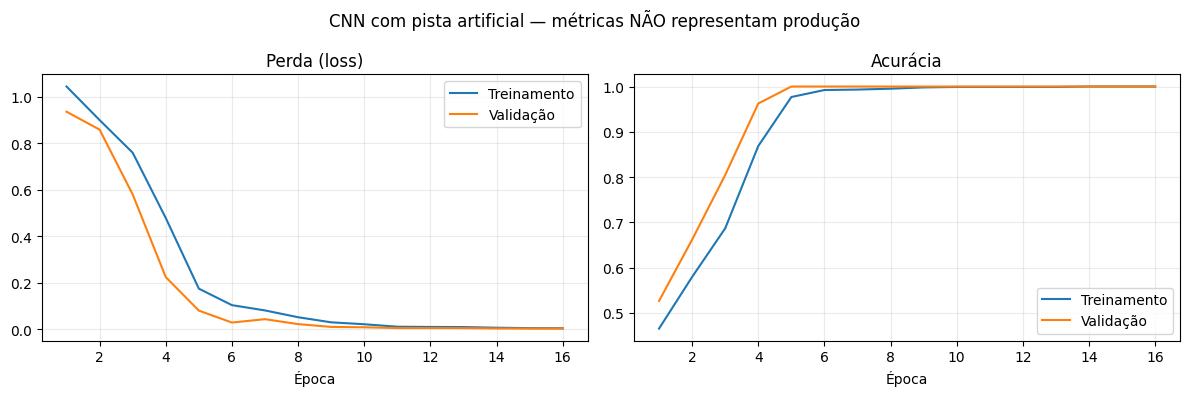

In [34]:
tf.keras.utils.set_random_seed(SEMENTE_ALEATORIA)
modelo_cnn_atalho = construir_cnn(
    usar_dropout=True, usar_regularizacao_l2=True
)
compilar_modelo(modelo_cnn_atalho, taxa_aprendizado=1e-3)

inicio_treinamento = time.perf_counter()
historico_atalho = modelo_cnn_atalho.fit(
    dados_treinamento_atalho,
    validation_data=dados_validacao_marca_correta,
    epochs=EPOCAS_ATALHO,
    callbacks=criar_callbacks(paciencia=4), verbose=2,
)
tempo_atalho = time.perf_counter() - inicio_treinamento
plotar_curvas_treinamento(historico_atalho,
                          'CNN com pista artificial — métricas NÃO representam produção')

### 11.2 A intervenção: mudar SOMENTE o quadrado

Vamos comparar três condições aplicadas às **mesmas imagens de validação**:

**A: Marca correspondente:** cor fabricada com base no verdadeiro rótulo.

**B: Marca trocada:** a cor muda, enquanto a fotografia e seu rótulo continuam iguais.

**C: Sem marca:** a fotografia original, sem a pista criada.

A condição A foi construída artificialmente usando o próprio rótulo (o que facilita a tarefa); ela não é uma medição independente de uso real. Nosso objetivo é estudar a **sensibilidade às marcas**, não produzir uma nova estimativa oficial de desempenho.

,condicao,acuracia,f1_macro
0,A: cor correspondente,1.000,1.000
1,B: cor trocada,0.023,0.022
2,C: sem marca,0.353,0.210


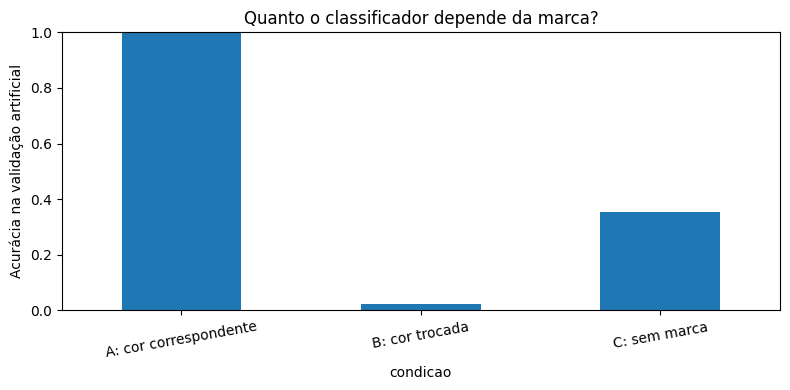

In [35]:
condicoes_atalho = {
    'A: cor correspondente': dados_validacao_marca_correta,
    'B: cor trocada': dados_validacao_marca_trocada,
    'C: sem marca': dados_validacao_sem_marca,
}
registros_condicoes_atalho = []
for nome_condicao, dataset_condicao in condicoes_atalho.items():
    metricas_condicao = avaliar_classificacao(
        modelo_cnn_atalho, dataset_condicao, mostrar_matriz=False
    )
    registros_condicoes_atalho.append({
        'condicao': nome_condicao,
        'acuracia': metricas_condicao['acuracia'],
        'f1_macro': metricas_condicao['f1_macro'],
    })

tabela_condicoes_atalho = pd.DataFrame(registros_condicoes_atalho)
display(tabela_condicoes_atalho.round(3))
eixo = tabela_condicoes_atalho.plot.bar(
    x='condicao', y='acuracia', figsize=(8, 4), legend=False, rot=10
)
eixo.set_ylabel('Acurácia na validação artificial')
eixo.set_ylim(0, 1)
eixo.set_title('Quanto o classificador depende da marca?')
plt.tight_layout()
plt.show()

### 11.3 Um controle realmente pareado

Selecionamos uma fotografia de validação e produzimos **três versões da mesma imagem**, incluindo uma versão com quadrado de outra classe. Isso controla a identidade da folha, a iluminação, o fundo e o enquadramento: só mudamos uma pequena região artificial.

Observaremos a pontuação softmax da **classe verdadeira** sob cada intervenção. As probabilidades representam saídas do modelo, não a certeza de que ele encontrou o critério biológico correto.

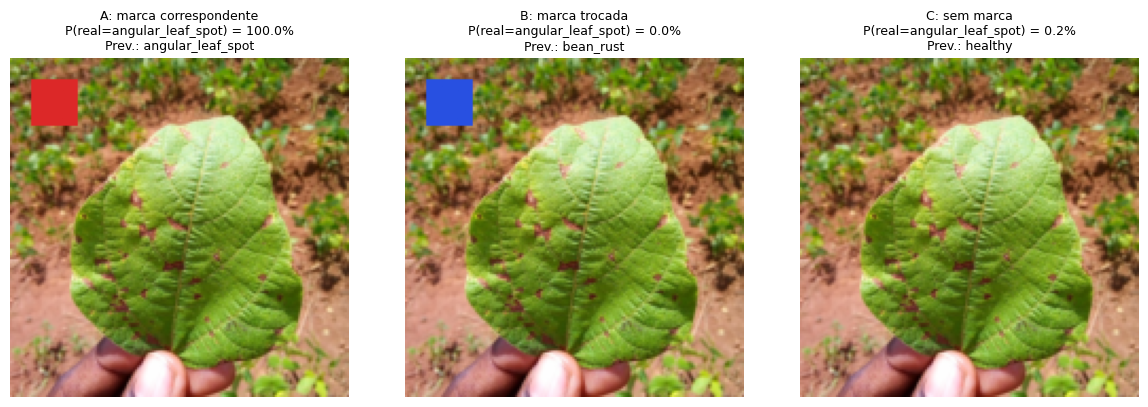

In [36]:
imagem_intervencao, rotulo_intervencao = next(iter(dados_validacao.unbatch()))
imagem_intervencao = imagem_intervencao.numpy()
rotulo_intervencao = int(rotulo_intervencao)

condicoes_imagem = {
    'A: marca correspondente': inserir_quadrados_em_lote(
        imagem_intervencao[None, ...], [rotulo_intervencao], 0
    )[0].numpy(),
    'B: marca trocada': inserir_quadrados_em_lote(
        imagem_intervencao[None, ...], [rotulo_intervencao], 1
    )[0].numpy(),
    'C: sem marca': imagem_intervencao,
}

figura, eixos = plt.subplots(1, 3, figsize=(12, 4))
for eixo, (nome_condicao, imagem_condicao) in zip(eixos, condicoes_imagem.items()):
    logits = modelo_cnn_atalho(imagem_condicao[None, ...], training=False)[0]
    probabilidades = tf.nn.softmax(logits).numpy()
    classe_prevista = int(np.argmax(probabilidades))
    eixo.imshow(imagem_condicao / 255.0)
    eixo.set_title(f'{nome_condicao}\n'
                   f'P(real={nomes_classes[rotulo_intervencao]}) = '
                   f'{probabilidades[rotulo_intervencao]:.1%}\n'
                   f'Prev.: {nomes_classes[classe_prevista]}', fontsize=9)
    eixo.axis('off')
plt.tight_layout()
plt.show()

### 11.4 Grad-CAM do modelo com atalho

Aqui temos **uma CNN pequena**, diferente da MobileNetV2. Precisamos obter os mapas da **última convolução** desta CNN. Construiremos um extrator a partir da camada `Conv2D` final e da saída de logits — reutilizando os pesos treinados. Grad-CAM continua sendo uma pista; a troca do quadrado é a intervenção que testa a sensibilidade.

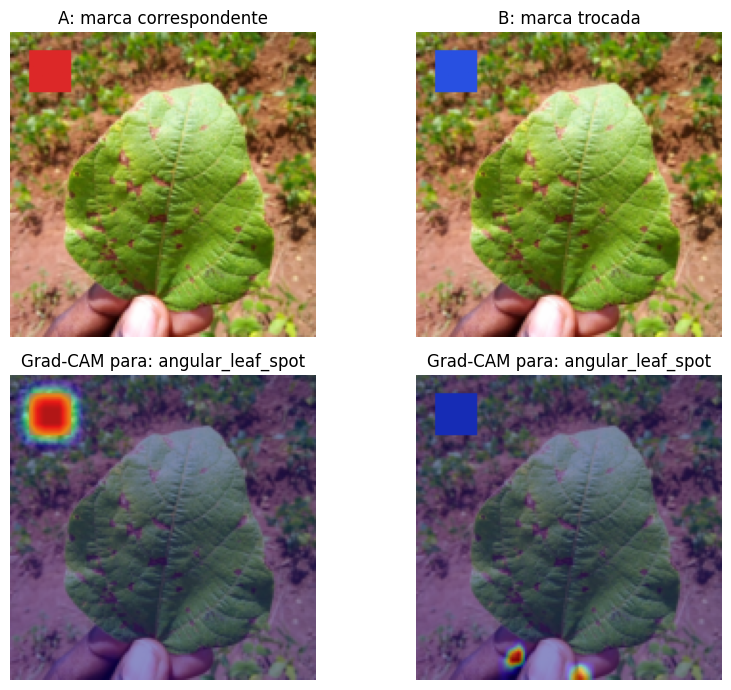

In [37]:
camadas_convolucionais_atalho = [
    camada for camada in modelo_cnn_atalho.layers
    if isinstance(camada, layers.Conv2D)
]
assert camadas_convolucionais_atalho
ultima_convolucao_atalho = camadas_convolucionais_atalho[-1]

extrator_gradcam_atalho = keras.Model(
    modelo_cnn_atalho.input,
    [ultima_convolucao_atalho.output, modelo_cnn_atalho.output],
    name='extrator_gradcam_cnn_atalho',
)

figura, eixos = plt.subplots(2, 2, figsize=(9, 7))
for coluna, nome_condicao in enumerate(['A: marca correspondente', 'B: marca trocada']):
    imagem_condicao = condicoes_imagem[nome_condicao]
    mapa_atalho = gerar_gradcam(
        extrator_gradcam_atalho, imagem_condicao, rotulo_intervencao
    )
    eixos[0, coluna].imshow(imagem_condicao / 255.0)
    eixos[0, coluna].set_title(nome_condicao)
    eixos[1, coluna].imshow(sobrepor_gradcam(imagem_condicao, mapa_atalho))
    eixos[1, coluna].set_title(f'Grad-CAM para: {nomes_classes[rotulo_intervencao]}')
    for linha in range(2):
        eixos[linha, coluna].axis('off')
plt.tight_layout()
plt.show()

### Conclusões que PODEMOS e NÃO PODEMOS tirar

Se a acurácia ou as pontuações mudarem muito quando trocamos a cor, teremos evidência de dependência da pista artificial **nesse modelo e nessas imagens**. Se não mudarem, o atalho pode não ter sido aprendido suficientemente nas condições escolhidas; o resultado **não deve ser forçado**.

- Grad-CAM pode destacar a região do quadrado, mas **não é obrigatório** que destaque, mesmo quando a intervenção afeta a previsão.
- Mudar a cor sem alterar a folha é um teste controlado de **sensibilidade da saída à intervenção**, não uma decomposição causal completa da rede.
- Métricas elevadas no conjunto **artificialmente marcado** não garantem que o modelo esteja reconhecendo doenças em condições reais.
- No experimento A, o rótulo verdadeiro foi utilizado para inserir a cor **também na validação**. Isso deve ser tratado como *condição artificial de diagnóstico*, não como uma validação independente de um sistema utilizável.

**Pergunta final:** por que a CNN do experimento do atalho **não concorre** com a MobileNetV2 pelo título de melhor modelo para folhas reais?

## 12. Comparar modelos sem olhar o teste

Chegou o momento de escolher um candidato para avaliar em dados de teste. A escolha foi feita somente a partir de **validação**: priorizamos **F1 macro**, depois acurácia; em caso de empate, consideramos menor tempo de treino.

O F1 macro trata as três classes com peso igual. A regra de seleção foi definida **antes de ver o teste**. O modelo de shortcut foi excluído porque foi treinado em imagens com pista artificial correlacionada ao rótulo.

**Cuidado:** com 133 imagens, diferenças pequenas podem representar apenas poucos acertos. Essa seleção é didática e não substitui uma análise de incerteza mais cuidadosa.

In [38]:
tabela_resultados = pd.DataFrame(resultados_experimentos.values())
colunas_resultados = [
    'modelo', 'acuracia', 'f1_macro', 'epocas',
    'tempo_segundos', 'parametros_treinaveis',
]
display(tabela_resultados[colunas_resultados].sort_values(
    ['f1_macro', 'acuracia', 'tempo_segundos'],
    ascending=[False, False, True],
).round(3))

modelos_candidatos = {
    'CNN básica': modelo_cnn_basico,
    'CNN + EarlyStopping': modelo_cnn_parada_antecipada,
    'CNN regularizada': modelo_cnn_regularizado,
    'CNN + aumentação': modelo_cnn_aumentado,
    'MobileNetV2 congelada': modelo_transferencia,
    'MobileNetV2 fine-tuning': modelo_ajuste_fino,
}

nome_modelo_final = sorted(
    resultados_experimentos,
    key=lambda nome: (
        -resultados_experimentos[nome]['f1_macro'],
        -resultados_experimentos[nome]['acuracia'],
        resultados_experimentos[nome]['tempo_segundos'],
    ),
)[0]
modelo_final = modelos_candidatos[nome_modelo_final]
print('Modelo escolhido usando SOMENTE validação:', nome_modelo_final)

,modelo,acuracia,f1_macro,epocas,tempo_segundos,parametros_treinaveis
5,MobileNetV2 fine-tuning,0.917,0.918,24,887.5,1198723
4,MobileNetV2 congelada,0.902,0.904,18,641.9,3843
1,CNN + EarlyStopping,0.774,0.775,21,1624.3,93635
0,CNN básica,0.767,0.764,25,1873.8,93635
2,CNN regularizada,0.752,0.754,25,1845.7,93635
3,CNN + aumentação,0.752,0.750,25,1873.6,93635


Modelo escolhido usando SOMENTE validação: MobileNetV2 fine-tuning


## 13. Teste final, uma única avaliação reservada

**Agora e somente agora** criaremos o pipeline do teste oficial. A mesma função determinística de redimensionamento será aplicada, sem aumentação aleatória. Não faremos novas escolhas de hiperparâmetros depois de observar os resultados.

A matriz de confusão e o recall por classe ajudam a evitar conclusões baseadas apenas em uma acurácia agregada. Diferencie claramente **validação usada na seleção** de **teste reservado para a estimativa final**.

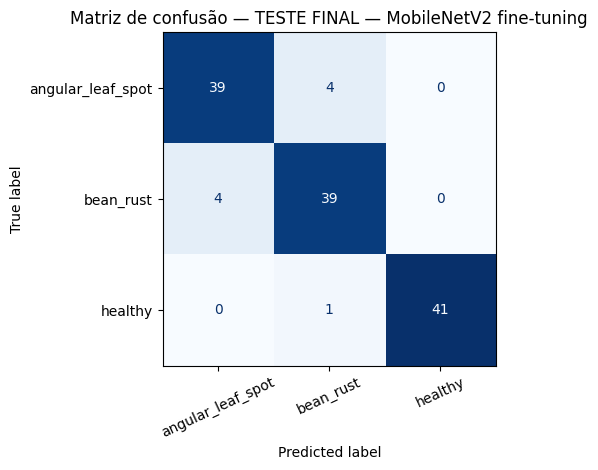

Acurácia de TESTE: 93.0%
F1 macro de TESTE: 0.930
Recall — angular_leaf_spot: 90.7%
Recall — bean_rust: 90.7%
Recall — healthy: 97.6%


In [39]:
dados_teste = preparar_dataset(dados_teste_brutos, treinamento=False)
metricas_teste = avaliar_classificacao(
    modelo_final, dados_teste, mostrar_matriz=True,
    titulo=f'TESTE FINAL — {nome_modelo_final}',
)
print('Acurácia de TESTE:', f"{metricas_teste['acuracia']:.1%}")
print('F1 macro de TESTE:', f"{metricas_teste['f1_macro']:.3f}")
for nome_classe in nomes_classes:
    print(f'Recall — {nome_classe}: {metricas_teste[f"recall_{nome_classe}"]:.1%}')

## 14. Retomada: o que aprendemos?

Responda com dados observados no notebook, não com generalizações:

1. **EDA:** quais características das fotos eram relevantes além de `shape` e rótulo? Quais riscos não puderam ser descartados sem metadados da planta/fazenda?
2. **Sobreajuste:** que evidências vimos nas curvas? Qual é a diferença entre acurácia de treinamento e generalização?
3. **Regularização:** o que mudou com EarlyStopping? Por que Dropout e L2 não devem ser tratados como garantias?
4. **Aumentação:** as transformações são plausíveis? Melhoraram a validação? Por que não criam amostras independentes?
5. **Transfer learning:** a MobileNetV2 congelada ajudou neste conjunto? Quantos parâmetros foram treinados?
6. **Fine-tuning:** valeu a pena adaptar parte da base, levando em conta o tempo?
7. **Grad-CAM:** os mapas de classes diferentes eram iguais? O que podemos e não podemos inferir a partir deles?
8. **Shortcuts:** o que mudou ao trocar apenas o quadrado? Por que o experimento marcado não representa avaliação realista?
9. **Teste:** qual foi a estimativa final? Ela pode ser extrapolada sem ressalvas para outras fazendas e câmeras?

### Continuação sugerida para os projetos

Adapte a mesma estrutura para Flowers, TrashNet, Cats vs Dogs ou reconhecimento de caracteres: documente o split, compare uma referência simples com transferência, use validação corretamente, inspecione erros e investigue pistas inesperadas.

**Referências:**
- [TFDS Beans](https://www.tensorflow.org/datasets/catalog/beans)
- [Keras: Transfer learning e fine-tuning](https://keras.io/guides/transfer_learning/)
- [Keras: Grad-CAM](https://keras.io/examples/vision/grad_cam/)
- [Keras: Image data augmentation](https://keras.io/api/layers/preprocessing_layers/image_augmentation/)
- Selvaraju et al. (2017), *Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization*.